This notebook analyses interesting SI-model snapshots on the Karate network.

In [32]:
import numpy as np
import pandas as pd
import pickle
import networkx as nx
import matplotlib as mpl
from matplotlib import pyplot as plt

import warnings

import propnetscore.node_selection as ns

In [33]:
with open("karate/network.gpickle", "rb") as f:
    G = pickle.load(f)
    adjacency_matrix = nx.to_numpy_array(G, weight=None)

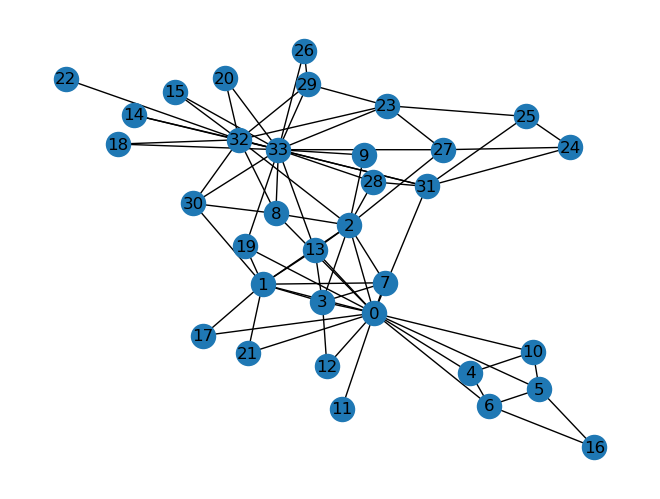

In [34]:
nx.draw(G, pos = nx.spring_layout(G), with_labels=True)

In [151]:
dfs = dict()

dfs[0] = pd.read_csv('karate/interesting_snapshots/source=0_run=38.csv')
dfs[1] = pd.read_csv('karate/interesting_snapshots/source=0_run=46.csv')
dfs[2] = pd.read_csv('karate/interesting_snapshots/source=0_run=71.csv')
dfs[3] = pd.read_csv('karate/interesting_snapshots/source=1_run=33.csv')
dfs[4] = pd.read_csv('karate/interesting_snapshots/source=1_run=70.csv')
dfs[5] = pd.read_csv('karate/interesting_snapshots/source=2_run=41.csv')
dfs[6] = pd.read_csv('karate/interesting_snapshots/source=33_run=15.csv')
dfs[7] = pd.read_csv('karate/interesting_snapshots/source=33_run=68.csv')
dfs[8] = pd.read_csv('karate/interesting_snapshots/source=33_run=81.csv')
dfs[9] = pd.read_csv('karate/interesting_snapshots/source=33_run=87.csv')

for i in range(10):
    dfs[i]["uniform"] = dfs[i]["infected"]
    dfs[i]["uniform"] = dfs[i]["uniform"]/dfs[i]["uniform"].sum()

In [144]:
dfs[2]

,node,infected,counts,true_prob,monte_carlo_n=10,soft_margin_a=0.4_n=10,soft_margin_a=0.3_n=10,soft_margin_a=0.2_n=10,soft_margin_a=0.15_n=10,soft_margin_a=0.1_n=10,...,soft_margin_a=0.1_n=1000,static_gnn_n=1000,monte_carlo_n=10000,soft_margin_a=0.4_n=10000,soft_margin_a=0.3_n=10000,soft_margin_a=0.2_n=10000,soft_margin_a=0.15_n=10000,soft_margin_a=0.1_n=10000,static_gnn_n=10000,uniform
0,0,1,23,0.056511,4.566097e-04,0.140412,0.155106,0.144805,9.789608e-02,1.470430e-02,...,2.579314e-03,0.058189,4.154277e-04,0.119110,0.117680,0.097812,0.079238,0.050133,0.084038,0.090909
1,1,1,6,0.014742,3.164900e-06,0.052248,0.023491,0.001614,3.285294e-05,2.306373e-10,...,8.220911e-02,0.028305,3.510147e-04,0.086958,0.074094,0.049395,0.032014,0.013135,0.032121,0.090909
2,2,0,0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,3,1,23,0.056511,2.253602e-04,0.070693,0.038677,0.003557,1.022517e-04,2.641961e-09,...,1.805355e-03,0.042379,3.243499e-03,0.089384,0.080254,0.065624,0.056494,0.029784,0.046241,0.090909
4,4,1,93,0.228501,8.112450e-02,0.119862,0.125242,0.079479,2.452375e-02,2.969135e-04,...,9.007029e-02,0.197756,2.961486e-01,0.108640,0.124473,0.154327,0.165715,0.110100,0.191418,0.090909
5,5,1,47,0.115479,8.142867e-03,0.053841,0.027215,0.001963,3.538852e-05,2.311805e-10,...,2.184765e-02,0.125002,1.726525e-01,0.105580,0.116297,0.124294,0.113263,0.098396,0.126015,0.090909
6,6,1,57,0.140049,6.910509e-02,0.129534,0.181694,0.352410,5.942404e-01,9.248077e-01,...,5.602453e-01,0.125002,1.588278e-01,0.104147,0.114950,0.131921,0.146165,0.173120,0.126015,0.090909
7,7,1,18,0.044226,3.576408e-03,0.052292,0.024857,0.001747,3.613031e-05,2.863432e-10,...,1.475363e-02,0.065053,8.864569e-03,0.087539,0.081010,0.070188,0.071478,0.116043,0.064676,0.090909
8,8,0,0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,9,0,0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [38]:
dfs[0].columns

Index(['node', 'infected', 'counts', 'true_prob', 'monte_carlo_n=10',
       'soft_margin_a=0.4_n=10', 'soft_margin_a=0.3_n=10',
       'soft_margin_a=0.2_n=10', 'soft_margin_a=0.15_n=10',
       'soft_margin_a=0.1_n=10', 'static_gnn_n=10', 'monte_carlo_n=100',
       'soft_margin_a=0.4_n=100', 'soft_margin_a=0.3_n=100',
       'soft_margin_a=0.2_n=100', 'soft_margin_a=0.15_n=100',
       'soft_margin_a=0.1_n=100', 'static_gnn_n=100', 'monte_carlo_n=1000',
       'soft_margin_a=0.4_n=1000', 'soft_margin_a=0.3_n=1000',
       'soft_margin_a=0.2_n=1000', 'soft_margin_a=0.15_n=1000',
       'soft_margin_a=0.1_n=1000', 'static_gnn_n=1000', 'monte_carlo_n=10000',
       'soft_margin_a=0.4_n=10000', 'soft_margin_a=0.3_n=10000',
       'soft_margin_a=0.2_n=10000', 'soft_margin_a=0.15_n=10000',
       'soft_margin_a=0.1_n=10000', 'static_gnn_n=10000'],
      dtype='object')

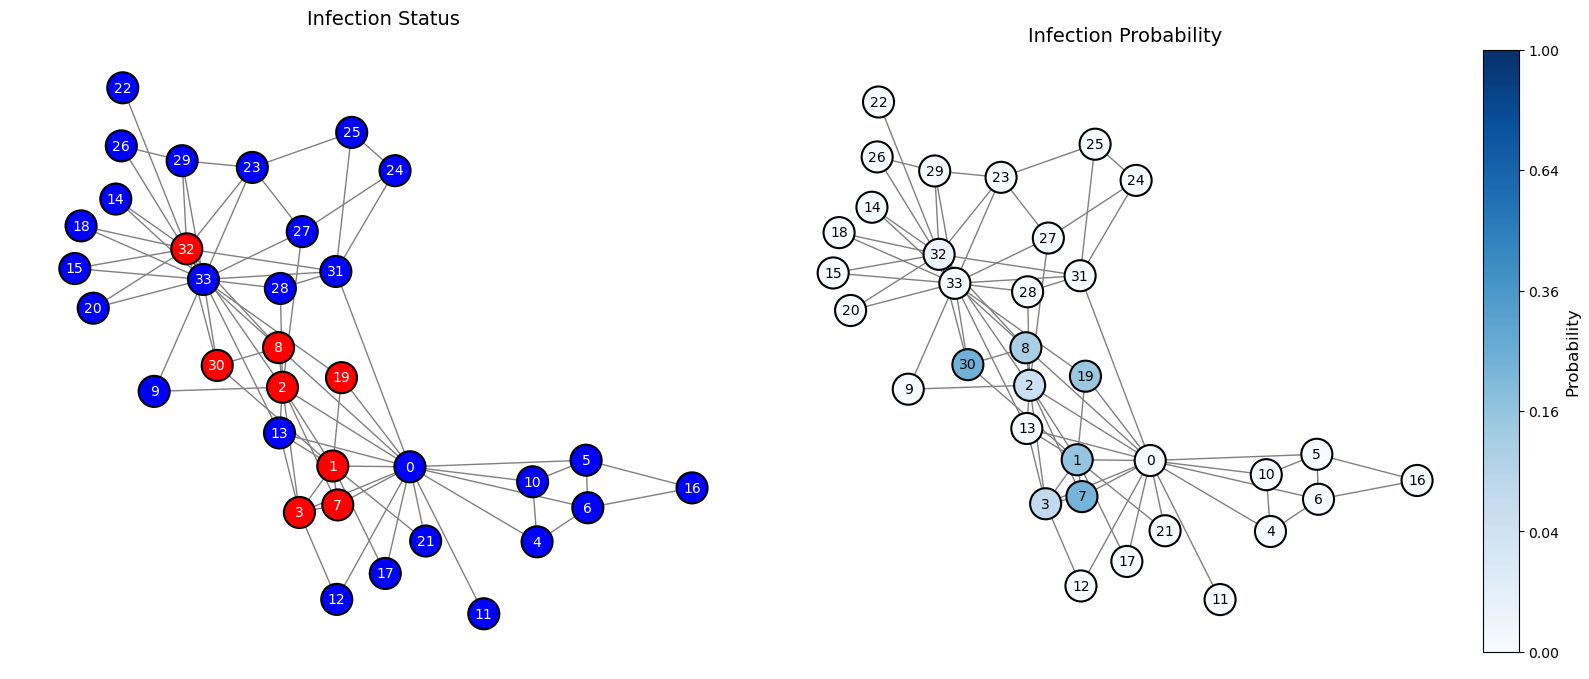

In [219]:
df = dfs[3]
models = ["true_prob", "static_gnn_n=10000", "soft_margin_a=0.2_n=10000", "soft_margin_a=0.1_n=10000", "monte_carlo_n=10000"]
model_pred = models[0] # "true_prob"  # column name of any of the probabilistic predictions

from mpl_toolkits.axes_grid1 import make_axes_locatable

# Create position layout (use same for both plots)
pos = nx.spring_layout(G, seed=42)  # seed for reproducibility

# Create dictionaries for faster lookup
df_indexed = df.set_index('node')
infected_dict = df_indexed['infected'].to_dict()
prob_dict = df_indexed[model_pred].to_dict()

# Get node colors/probabilities in the same order as G.nodes()
node_order = list(G.nodes())
node_colors_infected = ['red' if infected_dict[node] == 1 else 'blue' for node in node_order]
node_probs = [prob_dict[node] for node in node_order]

# Apply square root transformation to probabilities for better color distribution
node_probs_sqrt = np.sqrt(node_probs)  # Apply sqrt transformation

# Create figure with 2 subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# Plot 1: Infection status with solid borders
nx.draw(G, pos=pos, ax=ax1,
        node_color=node_colors_infected,
        with_labels=True,
        node_size=500,
        font_size=10,
        font_color='white',
        edgecolors='black',  # Solid black border around nodes
        linewidths=1.5,      # Border thickness
        edge_color='gray')
ax1.set_title("Infection Status", fontsize=14)

# Plot 2: Probability heatmap with sqrt transformation
# Draw nodes with borders
nodes = nx.draw_networkx_nodes(G, pos=pos, ax=ax2,
                               node_color=node_probs_sqrt,  # Use sqrt-transformed values
                               cmap=plt.cm.Blues,
                               node_size=500,
                               vmin=0, vmax=np.sqrt(1),  # Adjust vmax since sqrt(1) = 1
                               edgecolors='black',  # Solid black border
                               linewidths=1.5)      # Border thickness

# Draw edges and labels
nx.draw_networkx_edges(G, pos=pos, ax=ax2, edge_color='gray')
nx.draw_networkx_labels(G, pos=pos, ax=ax2, font_size=10)
ax2.set_title("Infection Probability", fontsize=14)

# Create colorbar INSIDE the second plot
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)

# Create custom ticks for colorbar to show original probability values
# We'll show sqrt-transformed values on the colorbar but label with original values
cbar = plt.colorbar(nodes, cax=cax)

# Set custom tick labels to show original probability values
# Choose tick positions in sqrt-space, then square them for labels
ticks = np.linspace(0, np.sqrt(1), 6)  # 6 ticks from 0 to 1 in sqrt-space
tick_labels = [f"{tick**2:.2f}" for tick in ticks]  # Square to get original values
cbar.set_ticks(ticks)
cbar.set_ticklabels(tick_labels)
cbar.set_label('Probability', fontsize=12)

# Remove the frame around the second plot (ax2)
ax2.set_frame_on(False)

# Set equal aspect ratio for both plots
ax1.set_aspect('equal')
ax2.set_aspect('equal')

# Remove axis ticks for cleaner look
ax1.set_xticks([])
ax1.set_yticks([])
ax2.set_xticks([])
ax2.set_yticks([])

# Turn off spines for ax2 (removes the frame)
for spine in ax2.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_13988\1791055706.py:139: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar


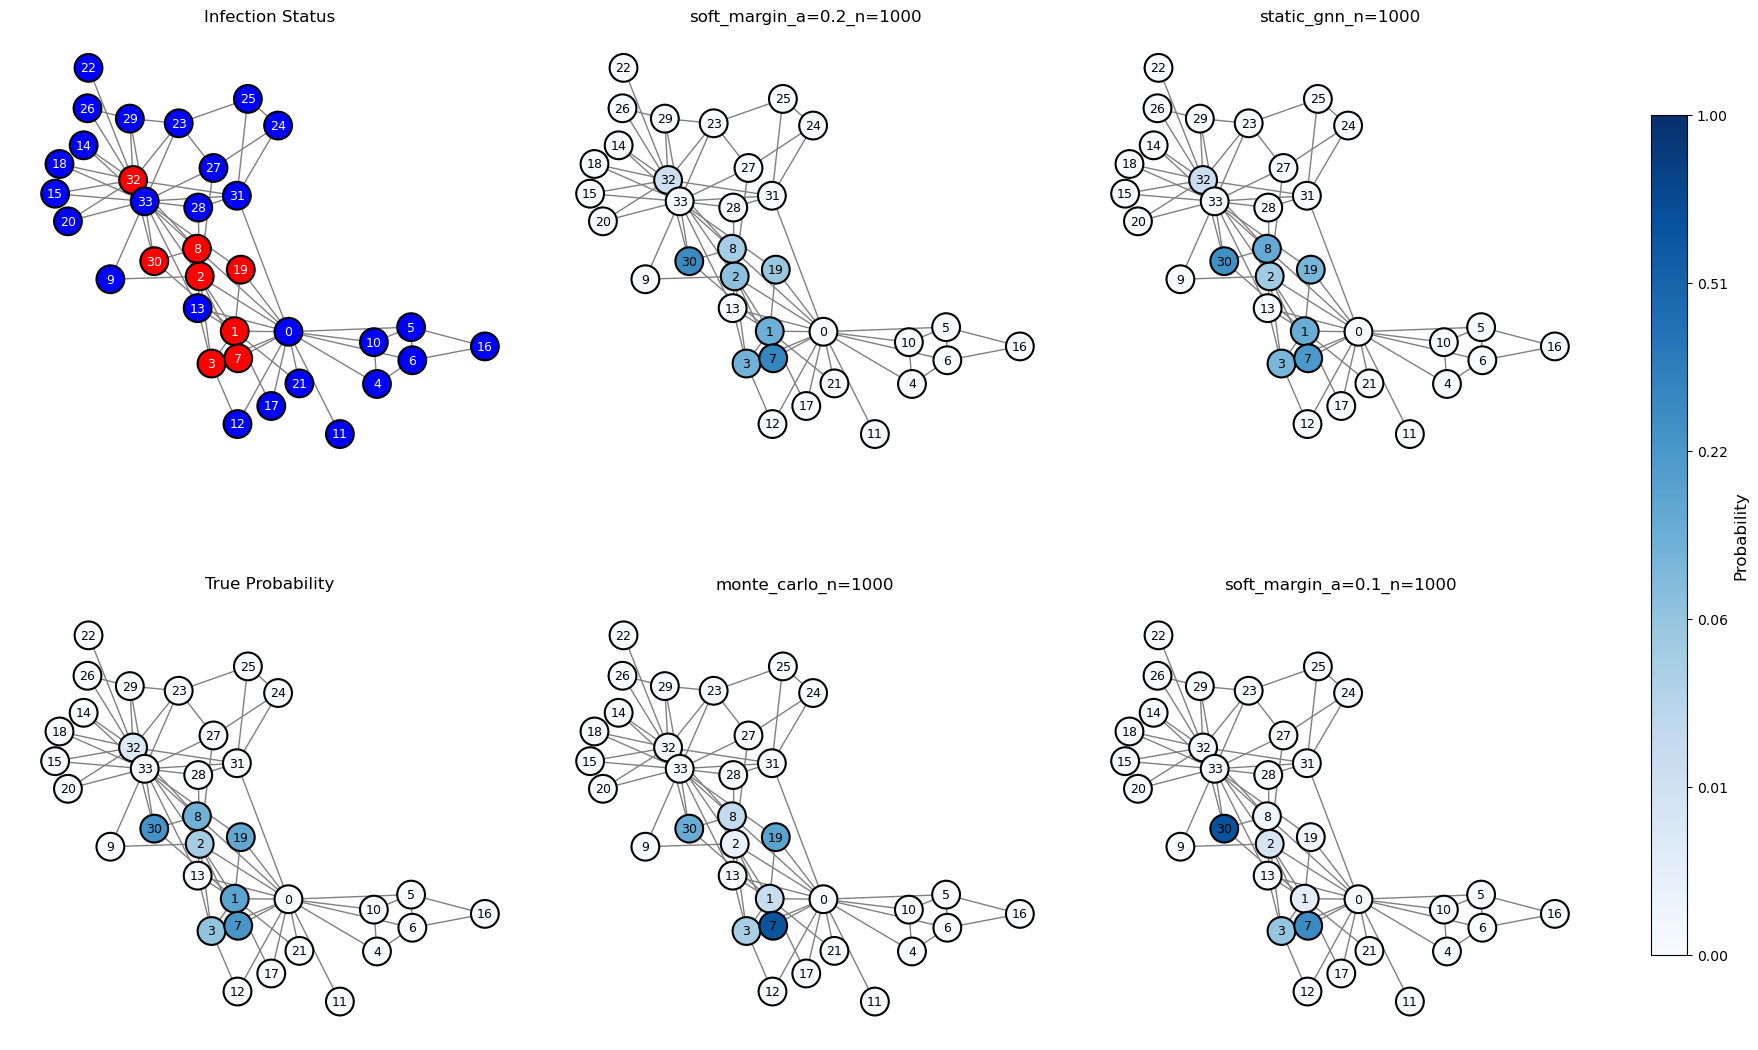

In [220]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

df = dfs[3]
models = ["true_prob", "static_gnn_n=1000", "soft_margin_a=0.2_n=1000", "soft_margin_a=0.1_n=1000", "monte_carlo_n=1000"]
models_to_plot = models[1:]  # The 4 models to plot on the right side

# Transformation parameter: a between 0 and 1
# a=0.5 gives sqrt transformation, a=1 gives linear, a=0 gives log-like (not exactly)
transformation_a = 1/3  # Change this value as needed

# Create position layout (use same for all plots)
pos = nx.spring_layout(G, seed=42)  # seed for reproducibility

# Get node order
node_order = list(G.nodes())

# Create dictionaries for faster lookup
df_indexed = df.set_index('node')
infected_dict = df_indexed['infected'].to_dict()

# Get node colors for infection status
node_colors_infected = ['red' if infected_dict[node] == 1 else 'blue' for node in node_order]

# Define transformation function
def transform_probs(probs, a):
    """Transform probabilities using x^a for a between 0 and 1"""
    return np.power(probs, a)

# Create figure with 2x3 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot 1 (upper left): Infection status with solid borders
ax = axes[0, 0]
nx.draw(G, pos=pos, ax=ax,
        node_color=node_colors_infected,
        with_labels=True,
        node_size=400,
        font_size=9,
        font_color='white',
        edgecolors='black',
        linewidths=1.5,
        edge_color='gray')
ax.set_title("Infection Status", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# Plot 2 (lower left): True probability
ax = axes[1, 0]
true_probs = df_indexed['true_prob'].to_dict()
node_probs_true = [true_probs[node] for node in node_order]
node_probs_transformed_true = transform_probs(np.array(node_probs_true), transformation_a)

nodes_true = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed_true,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)

nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
ax.set_title("True Probability", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_frame_on(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Plot the remaining 4 models
all_transformed_probs = [node_probs_transformed_true]  # Start with true probs for colorbar scaling

for i, model in enumerate(models_to_plot, start=1):
    row = (i - 1) // 2  # 0 for first two models (upper right), 1 for last two (lower right)
    col = i % 2 + 1  # 1 or 2 for column position
    
    ax = axes[row, col]
    
    # Get probabilities for this model
    prob_dict = df_indexed[model].to_dict()
    node_probs = [prob_dict[node] for node in node_order]
    node_probs_transformed = transform_probs(np.array(node_probs), transformation_a)
    all_transformed_probs.append(node_probs_transformed)  # Collect for colorbar scaling
    
    # Draw nodes
    nodes = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)
    
    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
    nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
    ax.set_title(model, fontsize=12)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

# Create one colorbar for all probability plots
# Calculate vmax from transformation of 1
vmax_transformed = transform_probs(np.array([1]), transformation_a)[0]

# Create a single colorbar on the right side
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]

# Create colorbar with transformed scale
norm = plt.Normalize(vmin=0, vmax=vmax_transformed)
sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cbar_ax)

# Set custom tick labels to show original probability values
# We need to show transformed tick positions but label with original values
ticks_transformed = np.linspace(0, vmax_transformed, 6)
# Inverse transform to get original probability values for labels
if transformation_a > 0:
    tick_labels = [f"{(tick ** (1/transformation_a)):.2f}" for tick in ticks_transformed]
else:
    # Handle a=0 case (though it's not really defined)
    tick_labels = [f"{tick:.2f}" for tick in ticks_transformed]
    
cbar.set_ticks(ticks_transformed)
cbar.set_ticklabels(tick_labels)
cbar.set_label('Probability', fontsize=12)
#cbar.ax.text(1.5, 1.02, f'Transformation: x^{transformation_a:.2f}', transform=cbar.ax.transAxes, fontsize=10, va='bottom')

plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar
plt.show()

In [140]:
def compute_scores_efficiently(adj_matrix, df, model_columns, scoring_rules):
    """
    More efficient version if NodeSelectionTask allows vectorization.
    
    Parameters:
    - scoring_rules: dict of {score_name: (method_name, params_dict)}
    """
    result_df = df.copy()
    nodes = df['node'].values
    
    for model_col in model_columns:
        predictions = df[model_col].values
        
        for score_name, (method_name, params) in scoring_rules.items():
            scores = []
            for i, node in enumerate(nodes):
                task = ns.NodeSelectionTask(adj_matrix, predictions, i)
                score_method = getattr(task, method_name)
                score = score_method(**params) if params else score_method()
                scores.append(score)
            
            result_df[f"{score_name}_{model_col}"] = scores
    
    return result_df

def compute_expected_scores(df, model_columns, scoring_rule_names):
    """
    Compute expected scores under true distribution.
    
    Returns a DataFrame with one row of expected scores for each model.
    """
    expected_scores = []
    
    for model_col in model_columns:
        model_scores = {}
        
        for score_name in scoring_rule_names:
            # Column name pattern: score_name_model_col
            score_col = f"{score_name}_{model_col}"
            
            # Expected score = Σ true_prob * score
            expected_score = np.dot(df['true_prob'].values, df[score_col].values)
            model_scores[f"{score_name}_expected"] = expected_score
        
        # Add model identifier
        model_scores['model'] = model_col
        expected_scores.append(model_scores)
    
    # Create DataFrame from expected scores
    expected_df = pd.DataFrame(expected_scores).set_index('model')
    
    return expected_df

def plot_simple_clean_heatmap(Escores_df):
    """Simple clean heatmap for your Escores_df."""
    # Convert to numpy
    data = Escores_df.values
    
    # Normalize by column max (so best in each column = 1)
    data_norm = data / data.max(axis=0, keepdims=True)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # Plot heatmap
    im = ax.imshow(data_norm, cmap='Greens', aspect='auto')
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax, shrink=0.8)
    cbar.set_label('Normalized Score (column max = 1.0)', rotation=-90, va="bottom")
    
    # Set labels
    ax.set_title('Model Performance Comparison', fontsize=14, pad=20)
    ax.set_xlabel('Evaluation Metrics', fontsize=12)
    ax.set_ylabel('Models', fontsize=12)
    
    # Set ticks
    n_metrics = Escores_df.shape[1]
    n_models = Escores_df.shape[0]
    
    ax.set_xticks(range(n_metrics))
    ax.set_yticks(range(n_models))
    
    # Clean metric names
    metric_names = [col.replace('_expected', '') for col in Escores_df.columns]
    
    ax.set_xticklabels(metric_names, rotation=45, ha='right', fontsize=10)
    ax.set_yticklabels(Escores_df.index, fontsize=10)
    
    # Add original values as text
    for i in range(n_models):
        for j in range(n_metrics):
            val = data[i, j]
            # Format based on value
            if abs(val) < 0.001:
                text = f'{val:.2e}'
            elif abs(val) < 0.1:
                text = f'{val:.4f}'
            elif abs(val) < 1:
                text = f'{val:.3f}'
            elif abs(val) < 10:
                text = f'{val:.2f}'
            else:
                text = f'{val:.1f}'
            
            # Choose text color
            if data_norm[i, j] < 0.6:
                color = 'black'
            else:
                color = 'white'
            
            ax.text(j, i, text, ha='center', va='center', 
                   color=color, fontsize=9)
    
    plt.tight_layout()
    return fig, ax



def plot_expected_scores_heatmap(Escores_df, normalize_by='minmax', cmap='Greens_r', figsize=(14, 6)):
    """
    Plot heatmap from your Escores_df DataFrame with multiple normalization options.
    
    Parameters:
    - Escores_df: DataFrame with models as index and _expected columns
    - normalize_by: 'minmax', 'max', 'rank', or None
    - cmap: colormap (for rank, this should be a sequential colormap like 'viridis_r')
    - figsize: figure size
    """
    # Extract the matrix
    matrix = Escores_df.values
    model_names = Escores_df.index.tolist()
    score_names = Escores_df.columns.tolist()
    
    # Clean score names for display (remove '_expected')
    display_score_names = [col.replace('_expected', '') for col in score_names]
    
    # ALL scores are lower=better
    # Apply normalization
    if normalize_by == 'rank':
        # RANK-BASED normalization
        n_models = len(model_names)
        matrix_norm = np.zeros_like(matrix, dtype=float)
        
        for j in range(matrix.shape[1]):
            col = matrix[:, j]
            
            # Since ALL scores are lower=better, sort ascending
            # argsort gives indices that would sort array in ascending order
            sorted_indices = np.argsort(col)  # Ascending: smallest first
            
            # Create ranks array: rank 1 = best (smallest), rank n = worst (largest)
            ranks = np.zeros_like(col, dtype=int)
            for rank, idx in enumerate(sorted_indices):
                ranks[idx] = rank + 1  # 1-based ranks
            
            # Convert ranks to 0-1 scale for coloring:
            # Best (rank 1) -> 1.0, Worst (rank n) -> 0.0
            # Formula: (n_models - rank) / (n_models - 1)
            matrix_norm[:, j] = (n_models - ranks) / (n_models - 1)
        
        cbar_label = 'Rank-based (1=best rank, 0=worst rank)'
        
    elif normalize_by == 'minmax':
        # MIN-MAX normalization (already correct for lower=better)
        col_min = matrix.min(axis=0, keepdims=True)
        col_max = matrix.max(axis=0, keepdims=True)
        range_vals = col_max - col_min
        
        # Avoid division by zero
        range_vals = np.where(range_vals == 0, 1, range_vals)
        
        # Normalize: (value - min) / (max - min)
        # But since lower is better, we need to REVERSE:
        # Best (lowest) should be 1, Worst (highest) should be 0
        matrix_norm = 1 - ((matrix - col_min) / range_vals)
        
        cbar_label = 'Score (min-max: 1=best, 0=worst)'
        
    elif normalize_by == 'max':
        # MAX normalization (adjusted for lower=better)
        col_min = matrix.min(axis=0, keepdims=True)
        
        # For lower=better metrics, normalize by inverse
        # We want: best (smallest) = 1, worst = approaching 0
        # One approach: normalized = min / value
        matrix_norm = np.zeros_like(matrix, dtype=float)
        for j in range(matrix.shape[1]):
            col = matrix[:, j]
            min_val = col.min()
            # Avoid division by zero
            if min_val == 0:
                # If min is 0, use transformation: 1 / (1 + value)
                matrix_norm[:, j] = 1 / (1 + col)
            else:
                matrix_norm[:, j] = min_val / col
        
        cbar_label = 'Score (inverse normalized: 1=best)'
        
    else:
        # No normalization
        matrix_norm = matrix
        cbar_label = 'Original Score (lower=better)'
    
    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create heatmap
    if normalize_by == 'rank':
        # For rank-based: use a sequential colormap where light=good, dark=bad
        # Using 'viridis_r' (reversed) so best (1.0) = light yellow, worst (0.0) = dark purple
        im = ax.imshow(matrix_norm, cmap='viridis', aspect='auto', vmin=0, vmax=1)
    else:
        # For others
        im = ax.imshow(matrix_norm, cmap=cmap, aspect='auto', vmin=0, vmax=1)
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label(cbar_label, rotation=-90, va="bottom")
    
    # Set labels
    title_map = {
        'rank': 'Model Comparison (Rank-based Normalization)',
        'minmax': 'Model Comparison (Min-Max Normalization)',
        'max': 'Model Comparison (Max Normalization)',
        None: 'Model Comparison (Raw Scores)'
    }
    ax.set_title(title_map.get(normalize_by, 'Model Comparison'), fontsize=16, pad=20)
    ax.set_xlabel('Scoring Rules (all: lower=better)', fontsize=12)
    ax.set_ylabel('Models', fontsize=12)
    
    # Set ticks
    ax.set_xticks(np.arange(len(score_names)))
    ax.set_yticks(np.arange(len(model_names)))
    
    ax.set_xticklabels(display_score_names, rotation=45, ha='right', fontsize=10)
    ax.set_yticklabels(model_names, fontsize=10)
    
    # Add text annotations with original values
    for i in range(len(model_names)):
        for j in range(len(score_names)):
            # Format based on magnitude
            val = matrix[i, j]
            if abs(val) >= 10:
                fmt = '{:.1f}'
            elif abs(val) >= 1:
                fmt = '{:.2f}'
            elif abs(val) >= 0.1:
                fmt = '{:.3f}'
            else:
                fmt = '{:.4f}'
            
            # Determine text color based on normalized value
            # For rank-based with viridis_r: dark colors need white text
            if normalize_by == 'rank':
                text_color = "white" if matrix_norm[i, j] < 0.5 else "black"
            else:
                text_color = "black" if matrix_norm[i, j] > 0.5 else "white"
            
            # For rank-based, also show the rank number
            if normalize_by == 'rank':
                # Calculate actual rank for display
                col = matrix[:, j]
                sorted_indices = np.argsort(col)  # Ascending
                rank = np.where(sorted_indices == i)[0][0] + 1  # 1-based rank
                annotation = f"{fmt.format(val)}\n(rank {rank})"
                font_size = 8
            else:
                annotation = fmt.format(val)
                font_size = 9
            
            ax.text(j, i, annotation,
                   ha="center", va="center", 
                   color=text_color,
                   fontsize=font_size)
    
    # Add grid
    ax.set_xticks(np.arange(len(score_names)+1)-0.5, minor=True)
    ax.set_yticks(np.arange(len(model_names)+1)-0.5, minor=True)
    #ax.grid(which="minor", color="gray", linestyle='-', linewidth=0.5, alpha=0.5)
    ax.tick_params(which="minor", bottom=False, left=False)
    
    # Add note about all scores being lower=better
    ax.text(0.02, 1.02, 'All metrics: lower values are better', 
            transform=ax.transAxes, fontsize=10,
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    return fig, ax, matrix_norm


In [368]:
scoring_rules = {
    "top_1_err": ("top_k_error_rate", {"k": 1}),
    "top_3_err": ("top_k_error_rate", {"k": 3}),
    "top_5_err": ("top_k_error_rate", {"k": 5}),
    "rank": ("rank_score", {}),
    "resistance": ("resistance_score", {}),
    "laplace": ("laplace_score", {"convention": "positive"}), 
    "brier": ("brier_score", {}), 
    "diff_01": ("diffusion_score", {"kappa2": 0.1, "convention": "positive"}),
    "diff_03": ("diffusion_score", {"kappa2": 0.3, "convention": "positive"}),
    "diff_1": ("diffusion_score", {"kappa2": 1, "convention": "positive"}),
    "diff_3": ("diffusion_score", {"kappa2": 3, "convention": "positive"}),
    "diff_10": ("diffusion_score", {"kappa2": 10, "convention": "positive"}),
    "diff_30": ("diffusion_score", {"kappa2": 30, "convention": "positive"}),
    "diff_100": ("diffusion_score", {"kappa2": 100, "convention": "positive"})
}#, "top_k_err": ("top_k_error_rate", {})}

In [184]:
model_columns = ['true_prob', 'uniform', 'monte_carlo_n=100', 'monte_carlo_n=1000', 'monte_carlo_n=10000',
        'soft_margin_a=0.4_n=100', 'soft_margin_a=0.4_n=1000', 'soft_margin_a=0.4_n=10000',
       'soft_margin_a=0.2_n=100', 'soft_margin_a=0.2_n=1000', 'soft_margin_a=0.2_n=10000',
        'soft_margin_a=0.1_n=100', 'soft_margin_a=0.1_n=1000', 'soft_margin_a=0.1_n=10000',
        'static_gnn_n=100', 'static_gnn_n=1000', 'static_gnn_n=10000'
]

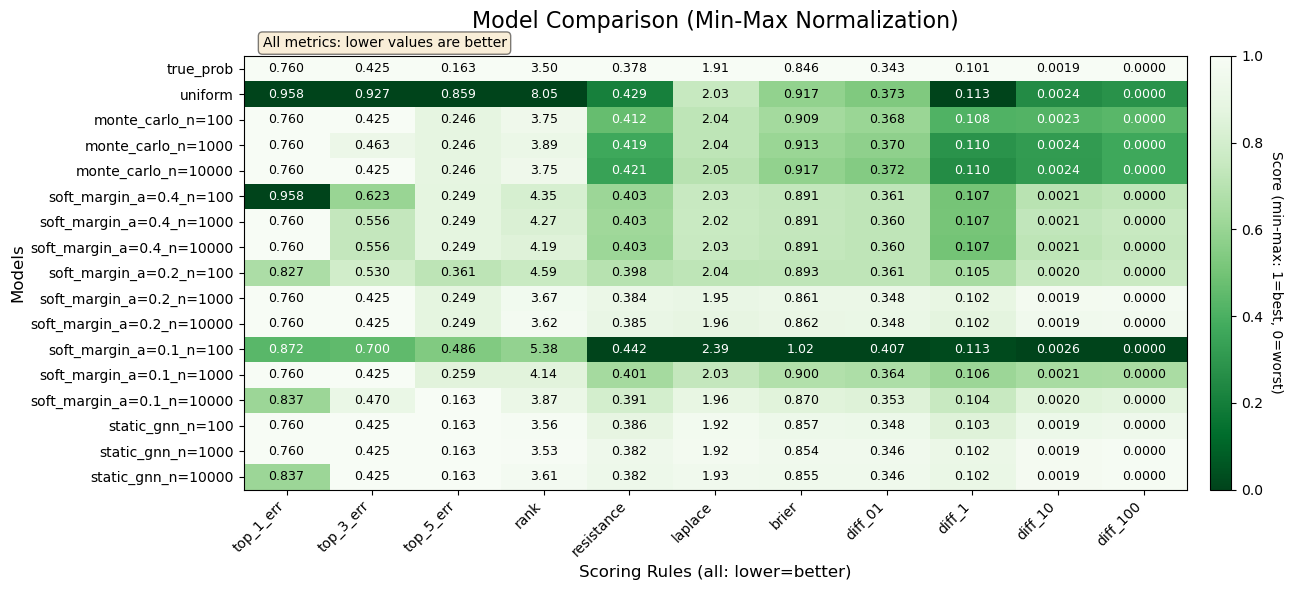

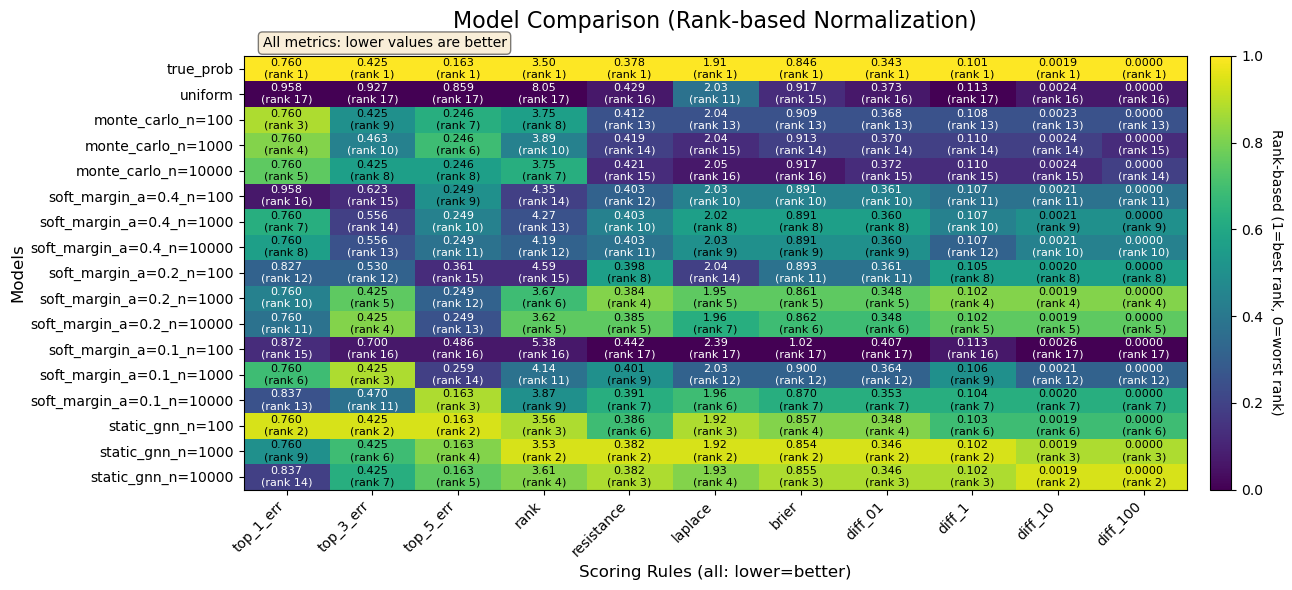

In [185]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[0], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

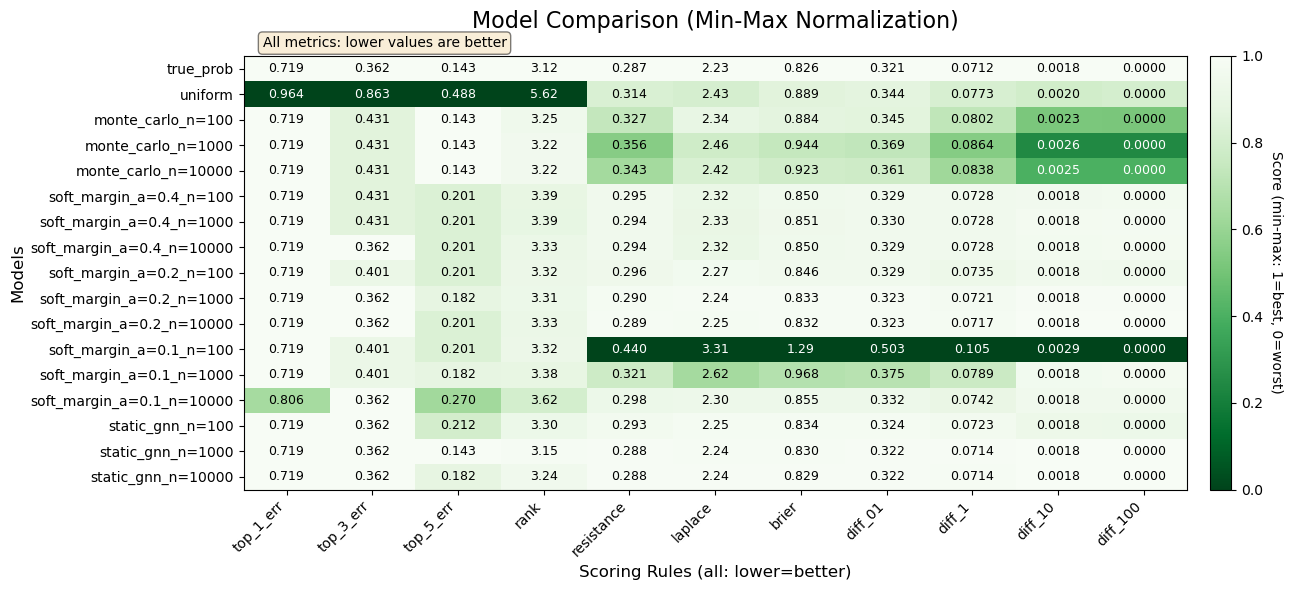

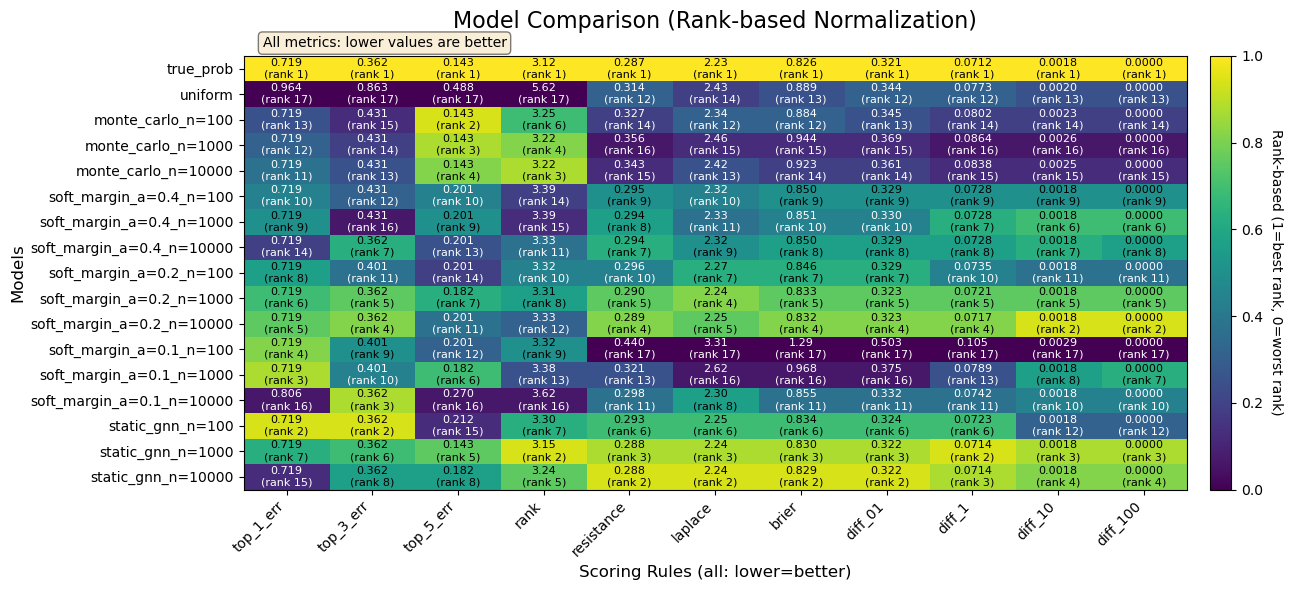

In [186]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[1], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

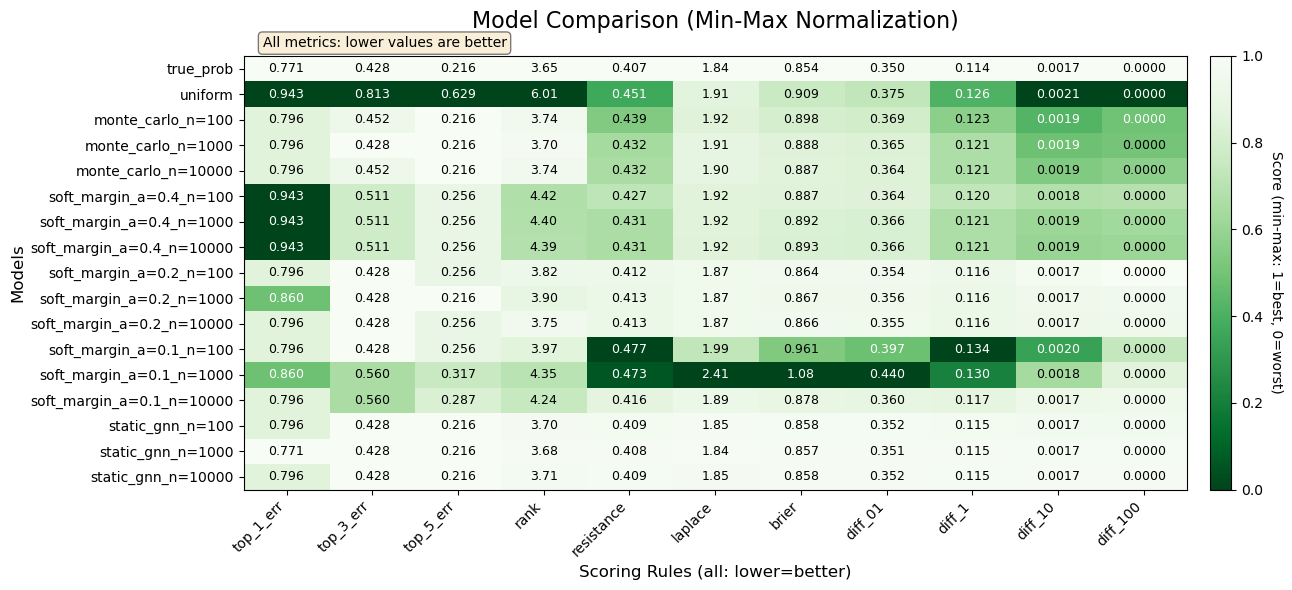

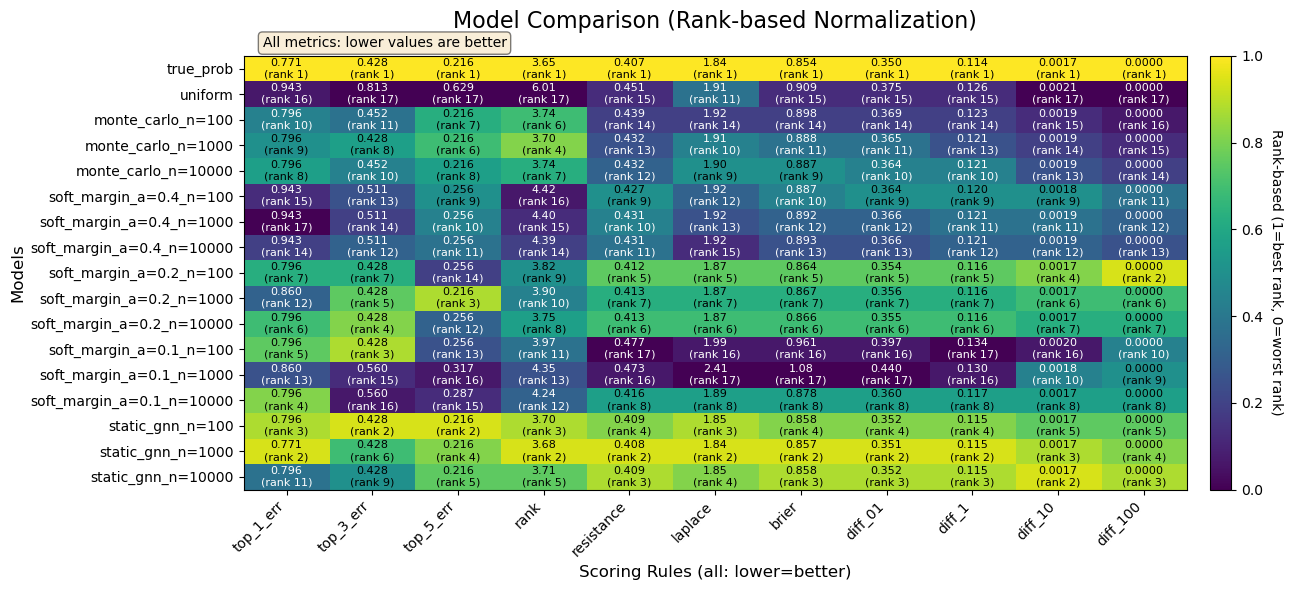

In [187]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[2], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

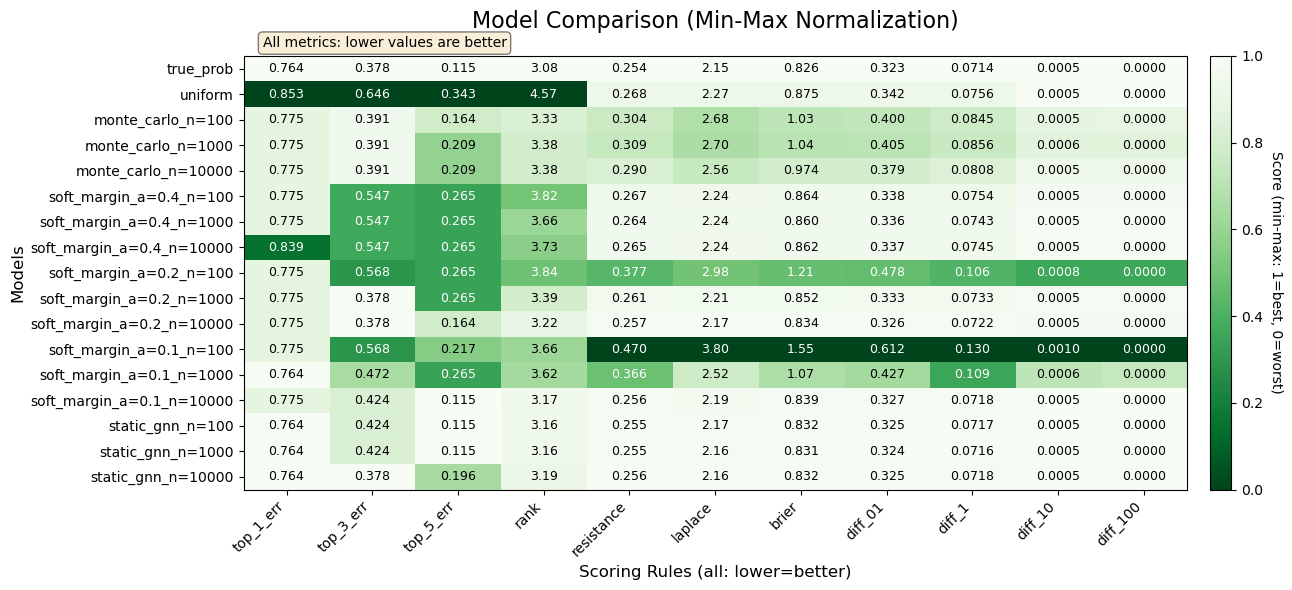

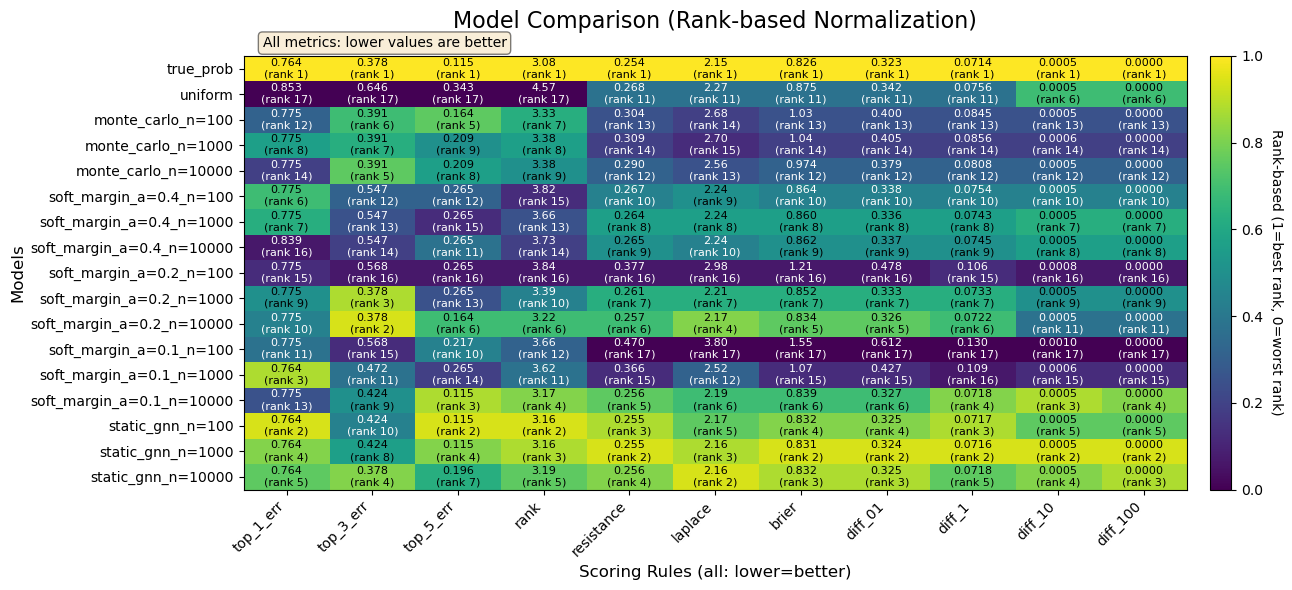

In [188]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[3], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

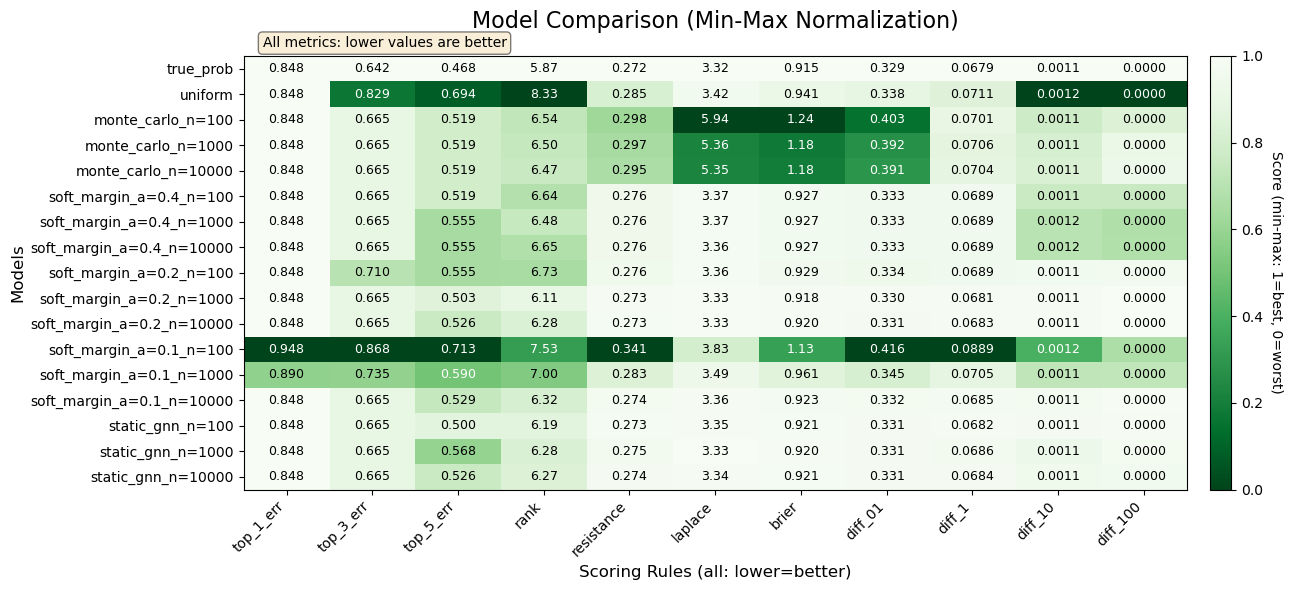

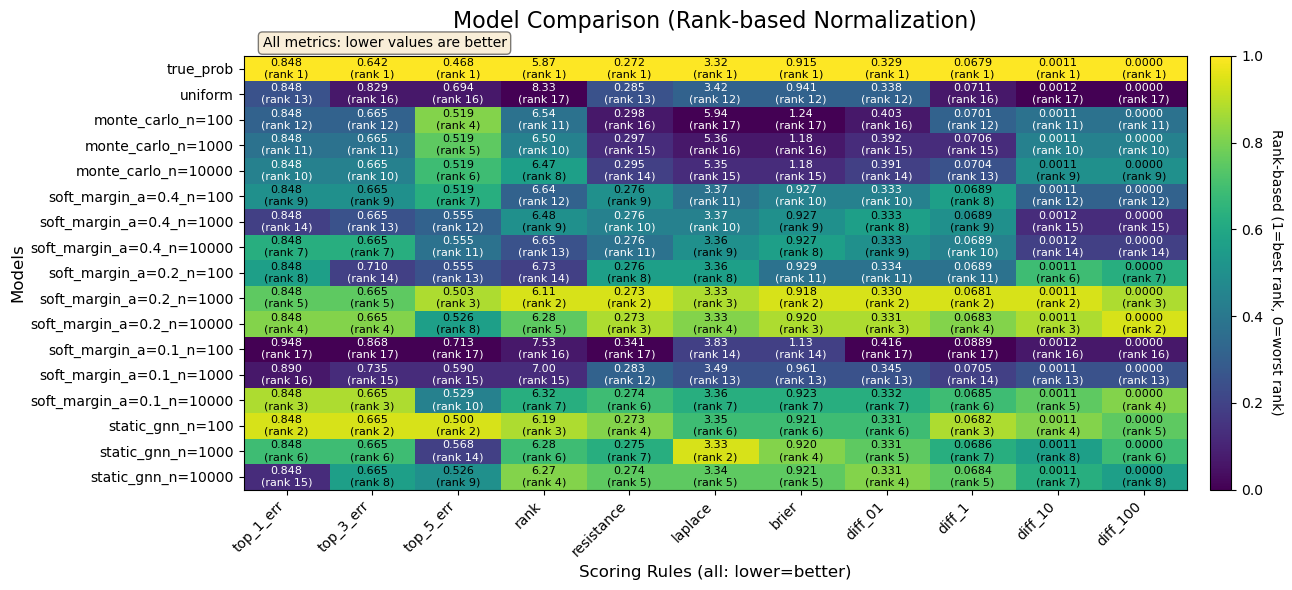

In [189]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[4], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

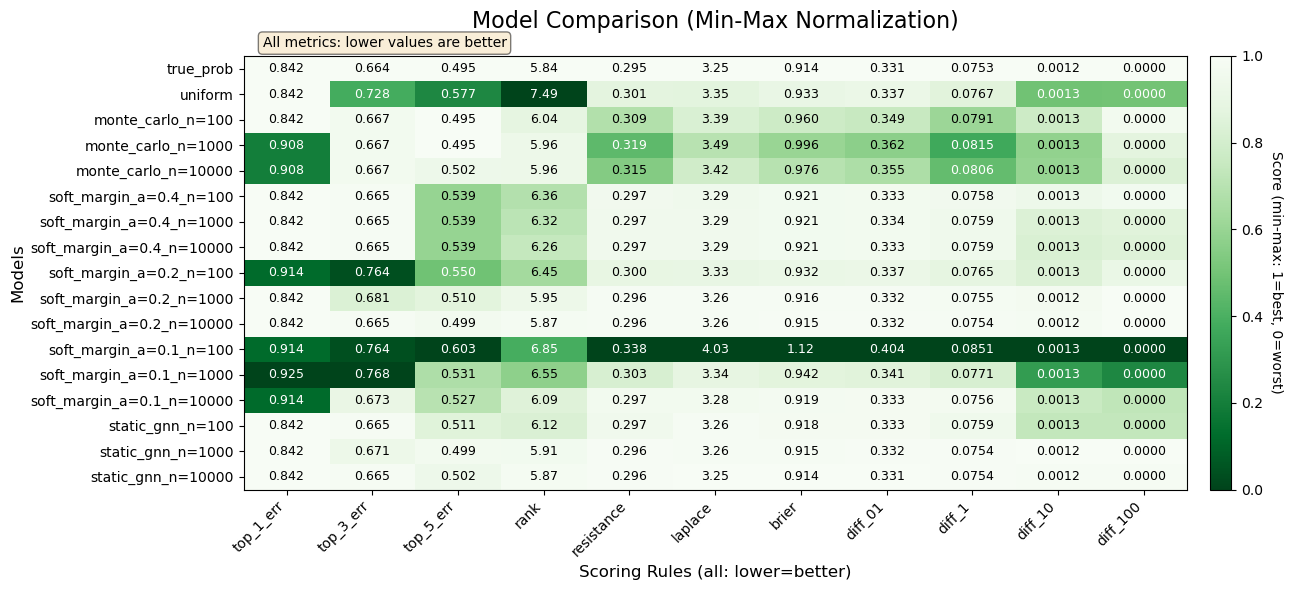

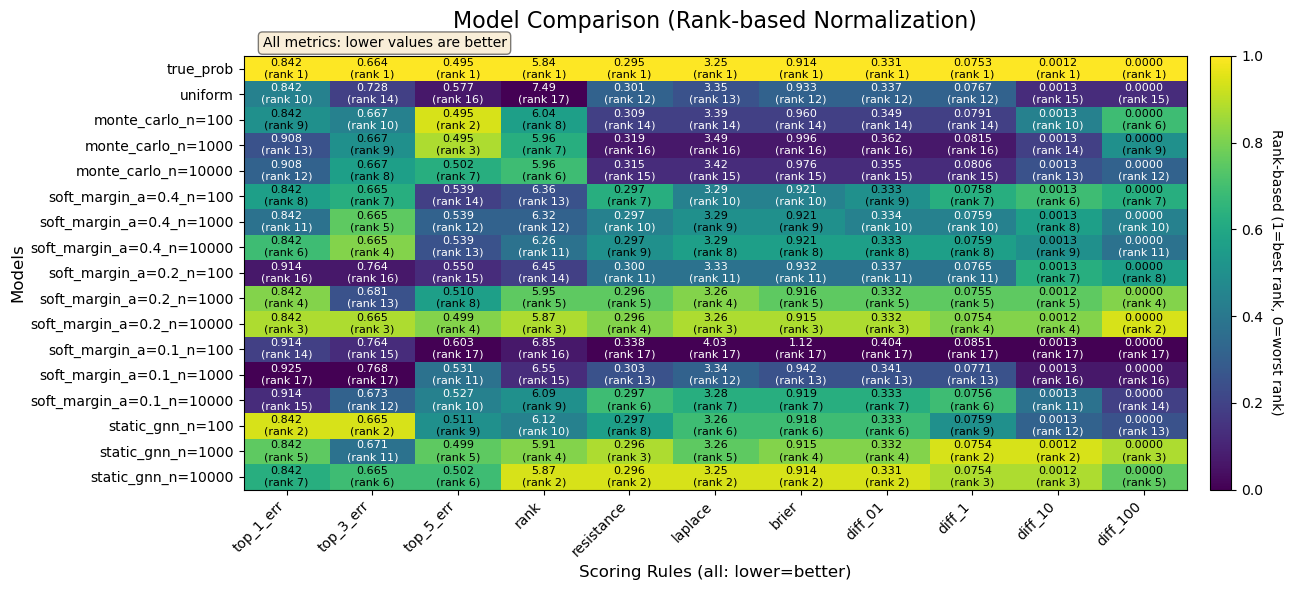

In [190]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[5], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

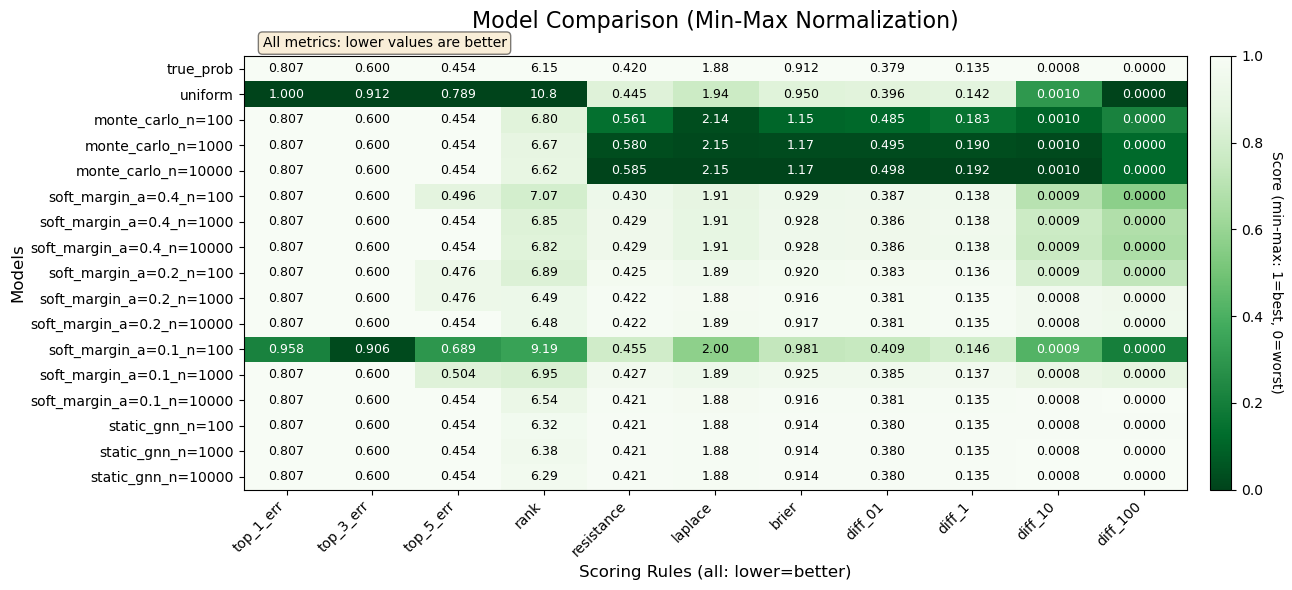

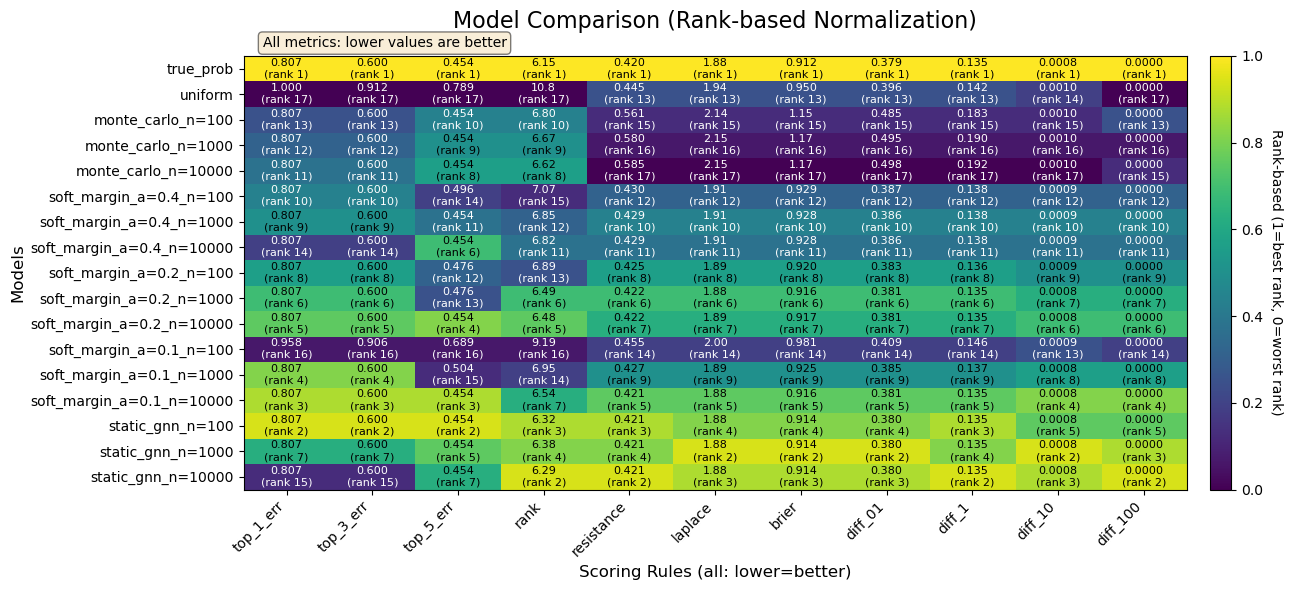

In [191]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[6], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

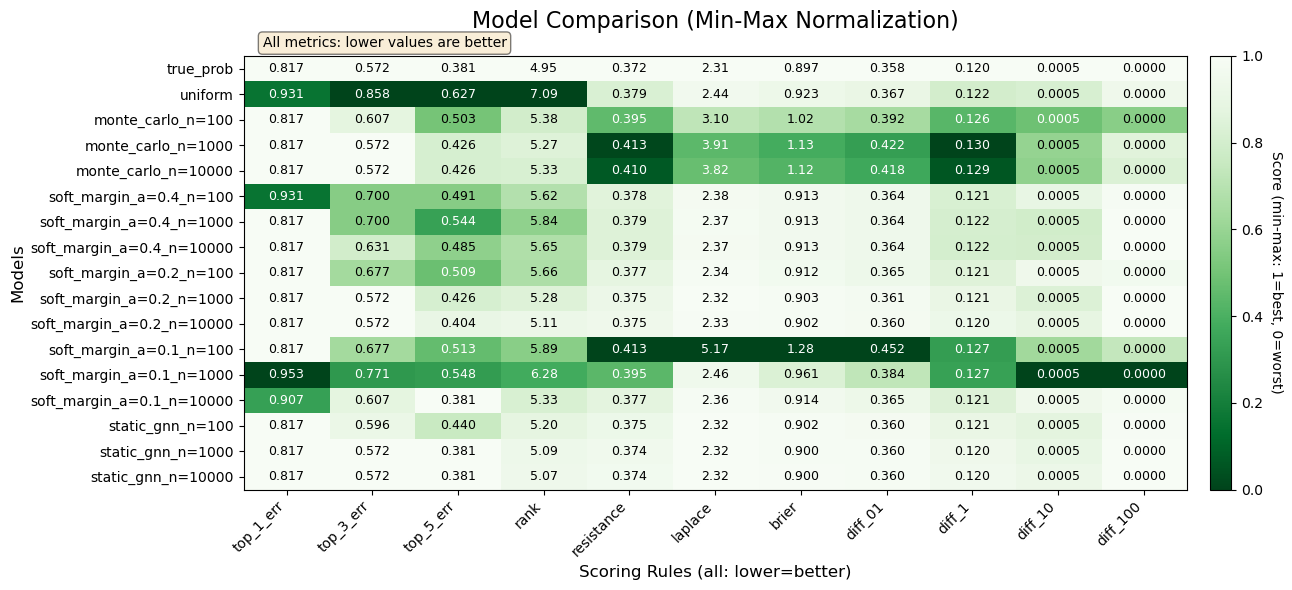

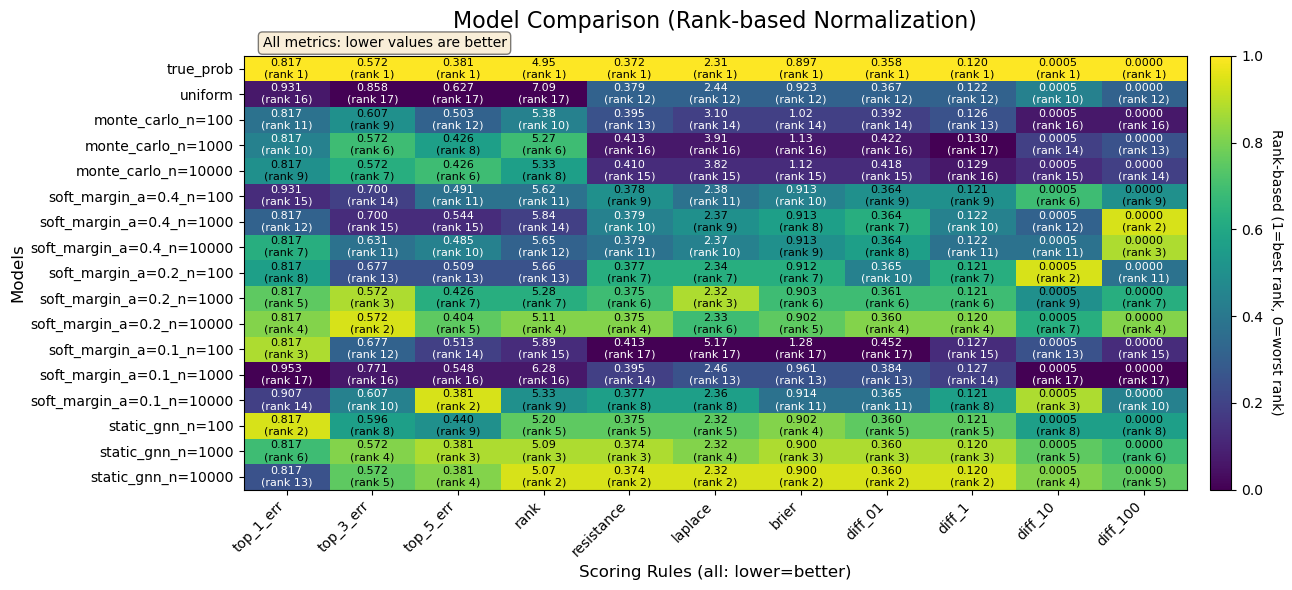

In [192]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[7], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

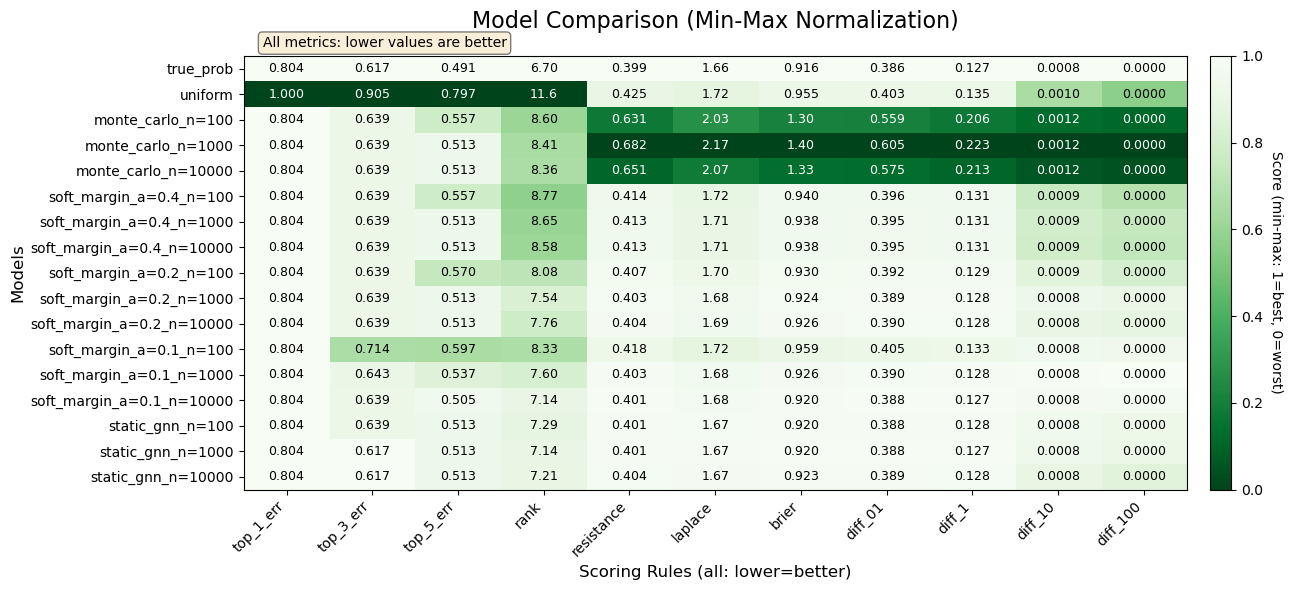

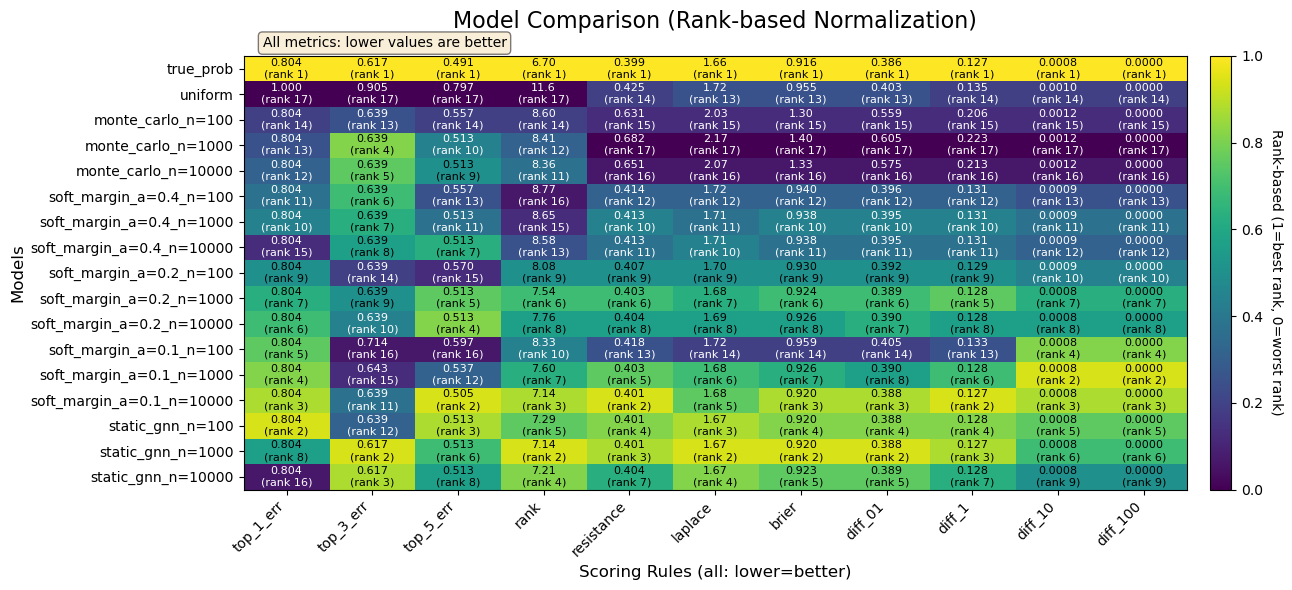

In [193]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[8], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

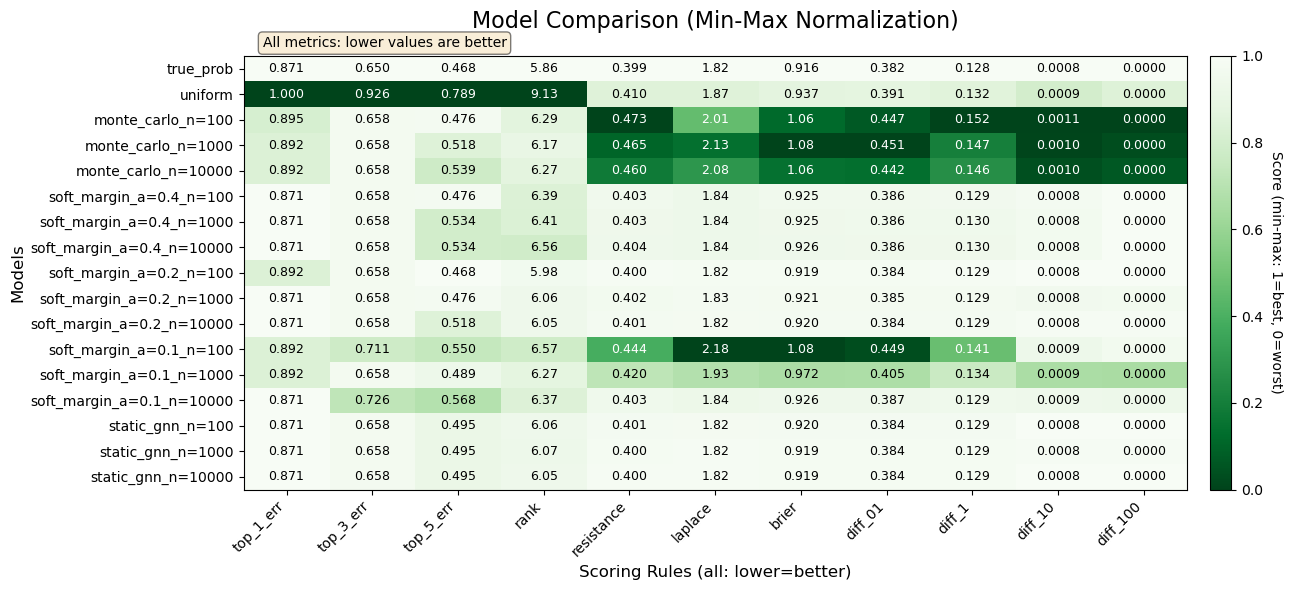

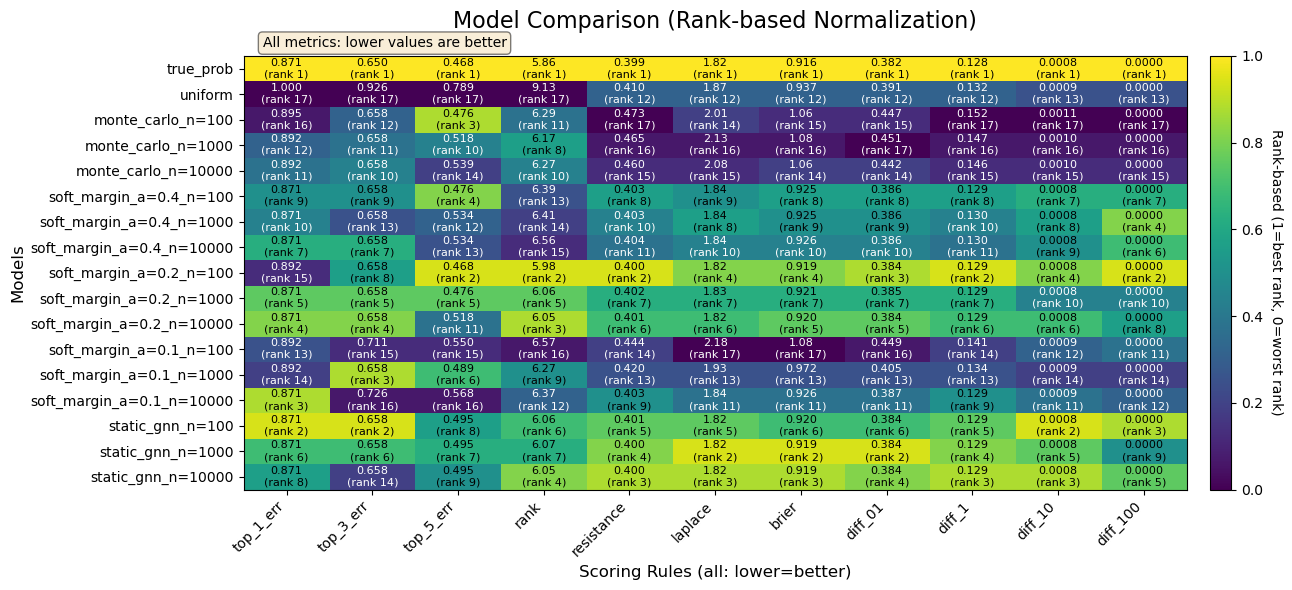

In [194]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[9], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

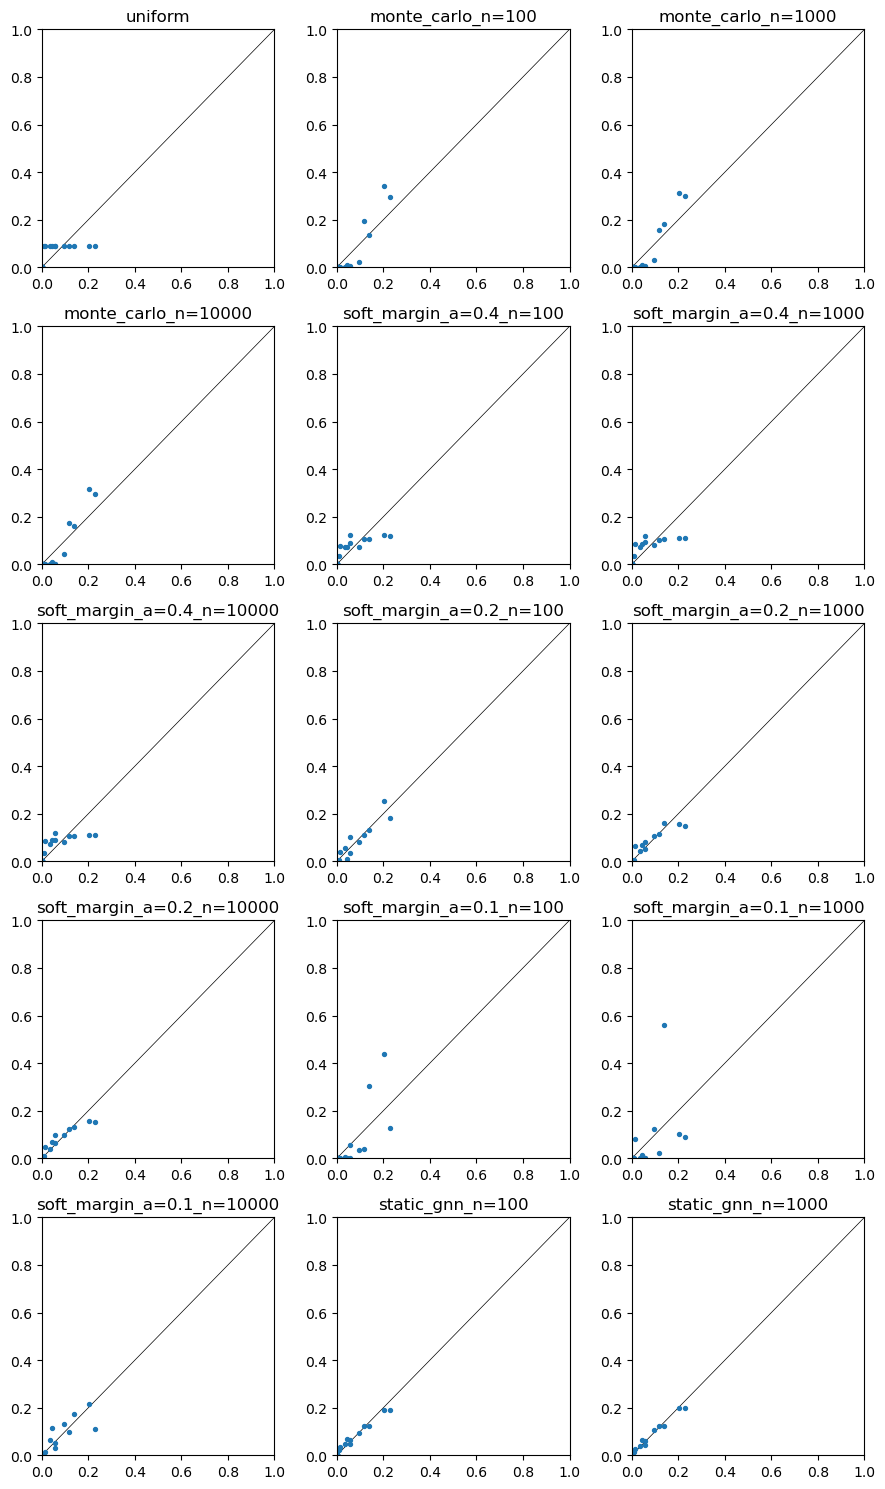

In [195]:
df = dfs[2]

fig, axs = plt.subplots(5, 3, figsize=(9,15))

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    ax.scatter(df["true_prob"], df[model_pred], s=8)
    ax.plot([0,1],[0,1], color="black", lw=0.5, zorder=-10)
    ax.set_title(model_pred)
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

### Example run 2 for paper

In [145]:
model_columns = ['true_prob', 'monte_carlo_n=1000', 
    'soft_margin_a=0.2_n=1000', 'static_gnn_n=10000', 'soft_margin_a=0.1_n=10000'
]

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_13988\943351551.py:138: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar


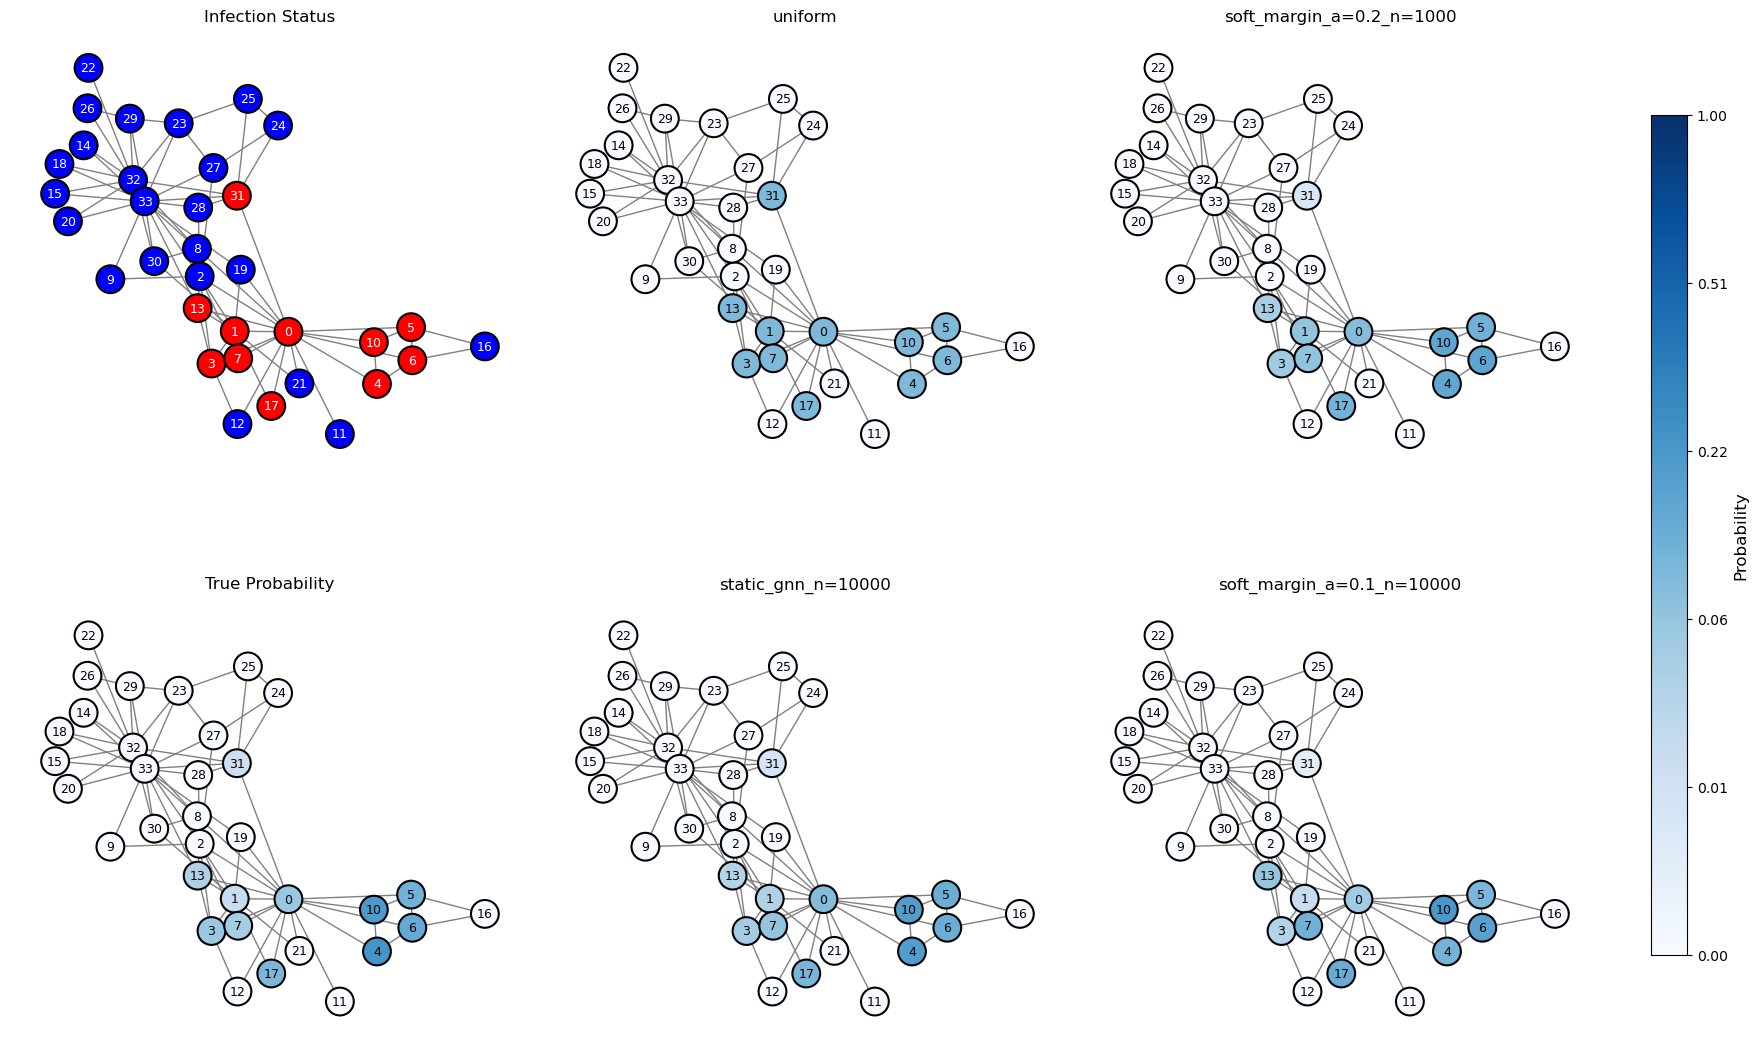

In [146]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

df = dfs[2]
models_to_plot = model_columns[1:]  # The 4 models to plot on the right side

# Transformation parameter: a between 0 and 1
# a=0.5 gives sqrt transformation, a=1 gives linear, a=0 gives log-like (not exactly)
transformation_a = 1/3  # Change this value as needed

# Create position layout (use same for all plots)
pos = nx.spring_layout(G, seed=42)  # seed for reproducibility

# Get node order
node_order = list(G.nodes())

# Create dictionaries for faster lookup
df_indexed = df.set_index('node')
infected_dict = df_indexed['infected'].to_dict()

# Get node colors for infection status
node_colors_infected = ['red' if infected_dict[node] == 1 else 'blue' for node in node_order]

# Define transformation function
def transform_probs(probs, a):
    """Transform probabilities using x^a for a between 0 and 1"""
    return np.power(probs, a)

# Create figure with 2x3 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot 1 (upper left): Infection status with solid borders
ax = axes[0, 0]
nx.draw(G, pos=pos, ax=ax,
        node_color=node_colors_infected,
        with_labels=True,
        node_size=400,
        font_size=9,
        font_color='white',
        edgecolors='black',
        linewidths=1.5,
        edge_color='gray')
ax.set_title("Infection Status", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# Plot 2 (lower left): True probability
ax = axes[1, 0]
true_probs = df_indexed['true_prob'].to_dict()
node_probs_true = [true_probs[node] for node in node_order]
node_probs_transformed_true = transform_probs(np.array(node_probs_true), transformation_a)

nodes_true = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed_true,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)

nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
ax.set_title("True Probability", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_frame_on(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Plot the remaining 4 models
all_transformed_probs = [node_probs_transformed_true]  # Start with true probs for colorbar scaling

for i, model in enumerate(models_to_plot, start=1):
    row = 0 if i <= 2 else 1  # 0 for first two models (top row), 1 for last two (bottom row)
    col = 1 if i % 2 == 1 else 2  # 1 for odd i (left), 2 for even i (right)
    
    ax = axes[row, col]
    
    # Get probabilities for this model
    prob_dict = df_indexed[model].to_dict()
    node_probs = [prob_dict[node] for node in node_order]
    node_probs_transformed = transform_probs(np.array(node_probs), transformation_a)
    all_transformed_probs.append(node_probs_transformed)  # Collect for colorbar scaling
    
    # Draw nodes
    nodes = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)
    
    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
    nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
    ax.set_title(model, fontsize=12)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

# Create one colorbar for all probability plots
# Calculate vmax from transformation of 1
vmax_transformed = transform_probs(np.array([1]), transformation_a)[0]

# Create a single colorbar on the right side
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]

# Create colorbar with transformed scale
norm = plt.Normalize(vmin=0, vmax=vmax_transformed)
sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cbar_ax)

# Set custom tick labels to show original probability values
# We need to show transformed tick positions but label with original values
ticks_transformed = np.linspace(0, vmax_transformed, 6)
# Inverse transform to get original probability values for labels
if transformation_a > 0:
    tick_labels = [f"{(tick ** (1/transformation_a)):.2f}" for tick in ticks_transformed]
else:
    # Handle a=0 case (though it's not really defined)
    tick_labels = [f"{tick:.2f}" for tick in ticks_transformed]
    
cbar.set_ticks(ticks_transformed)
cbar.set_ticklabels(tick_labels)
cbar.set_label('Probability', fontsize=12)
#cbar.ax.text(1.5, 1.02, f'Transformation: x^{transformation_a:.2f}', transform=cbar.ax.transAxes, fontsize=10, va='bottom')

plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar
plt.show()

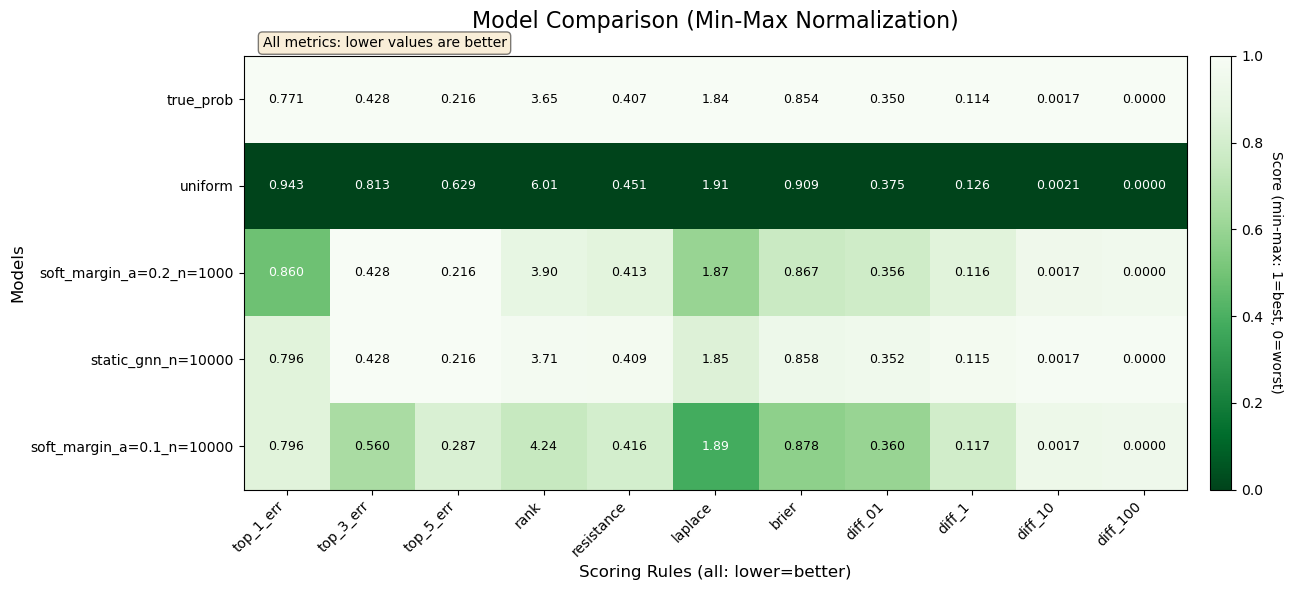

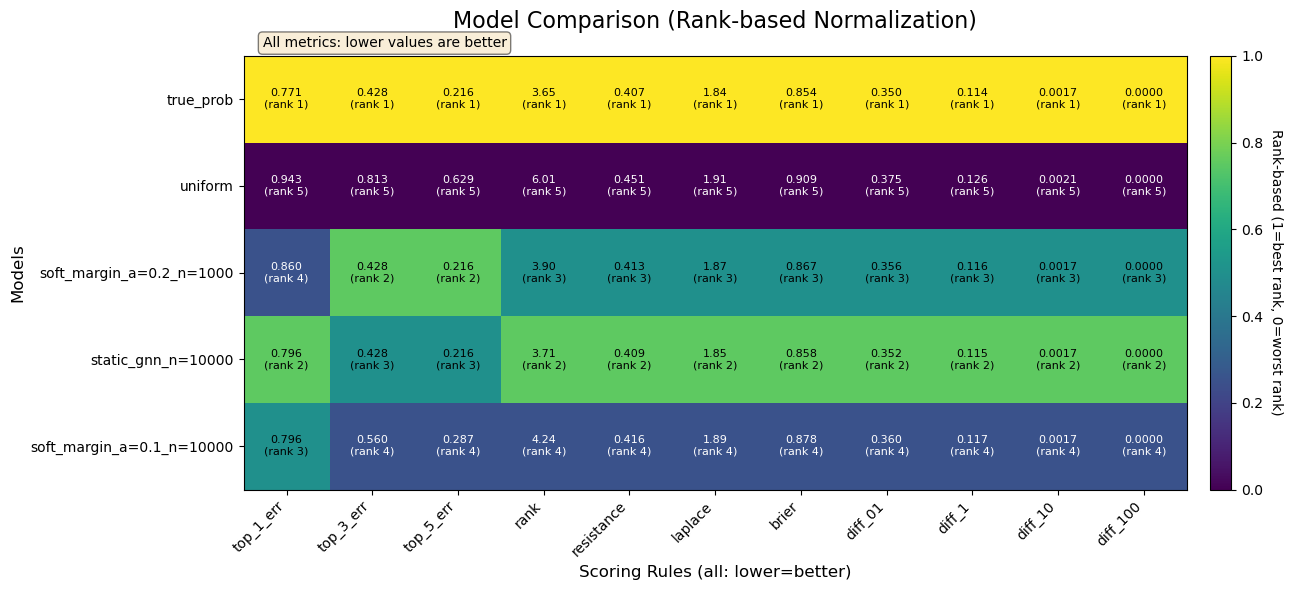

In [147]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[2], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

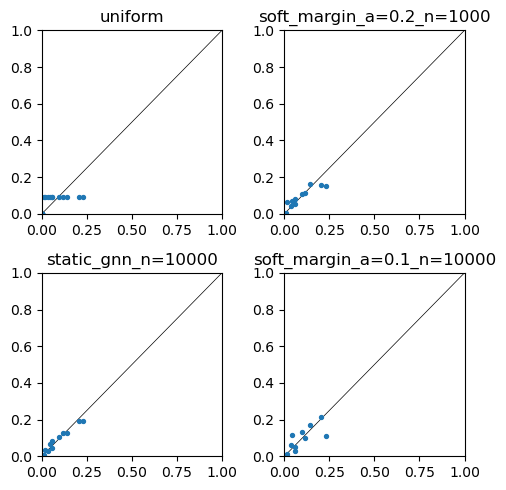

In [148]:
df = dfs[2]

fig, axs = plt.subplots(2, 2, figsize=(5,5))

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    ax.scatter(df["true_prob"], df[model_pred], s=8)
    ax.plot([0,1],[0,1], color="black", lw=0.5, zorder=-10)
    ax.set_title(model_pred)
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

### Example run 1 for paper

In [171]:
model_columns = ['true_prob', 'monte_carlo_n=10000', 
    'soft_margin_a=0.4_n=10000', 'static_gnn_n=10000', 'soft_margin_a=0.2_n=10000'
]

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_13988\1831431318.py:138: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar


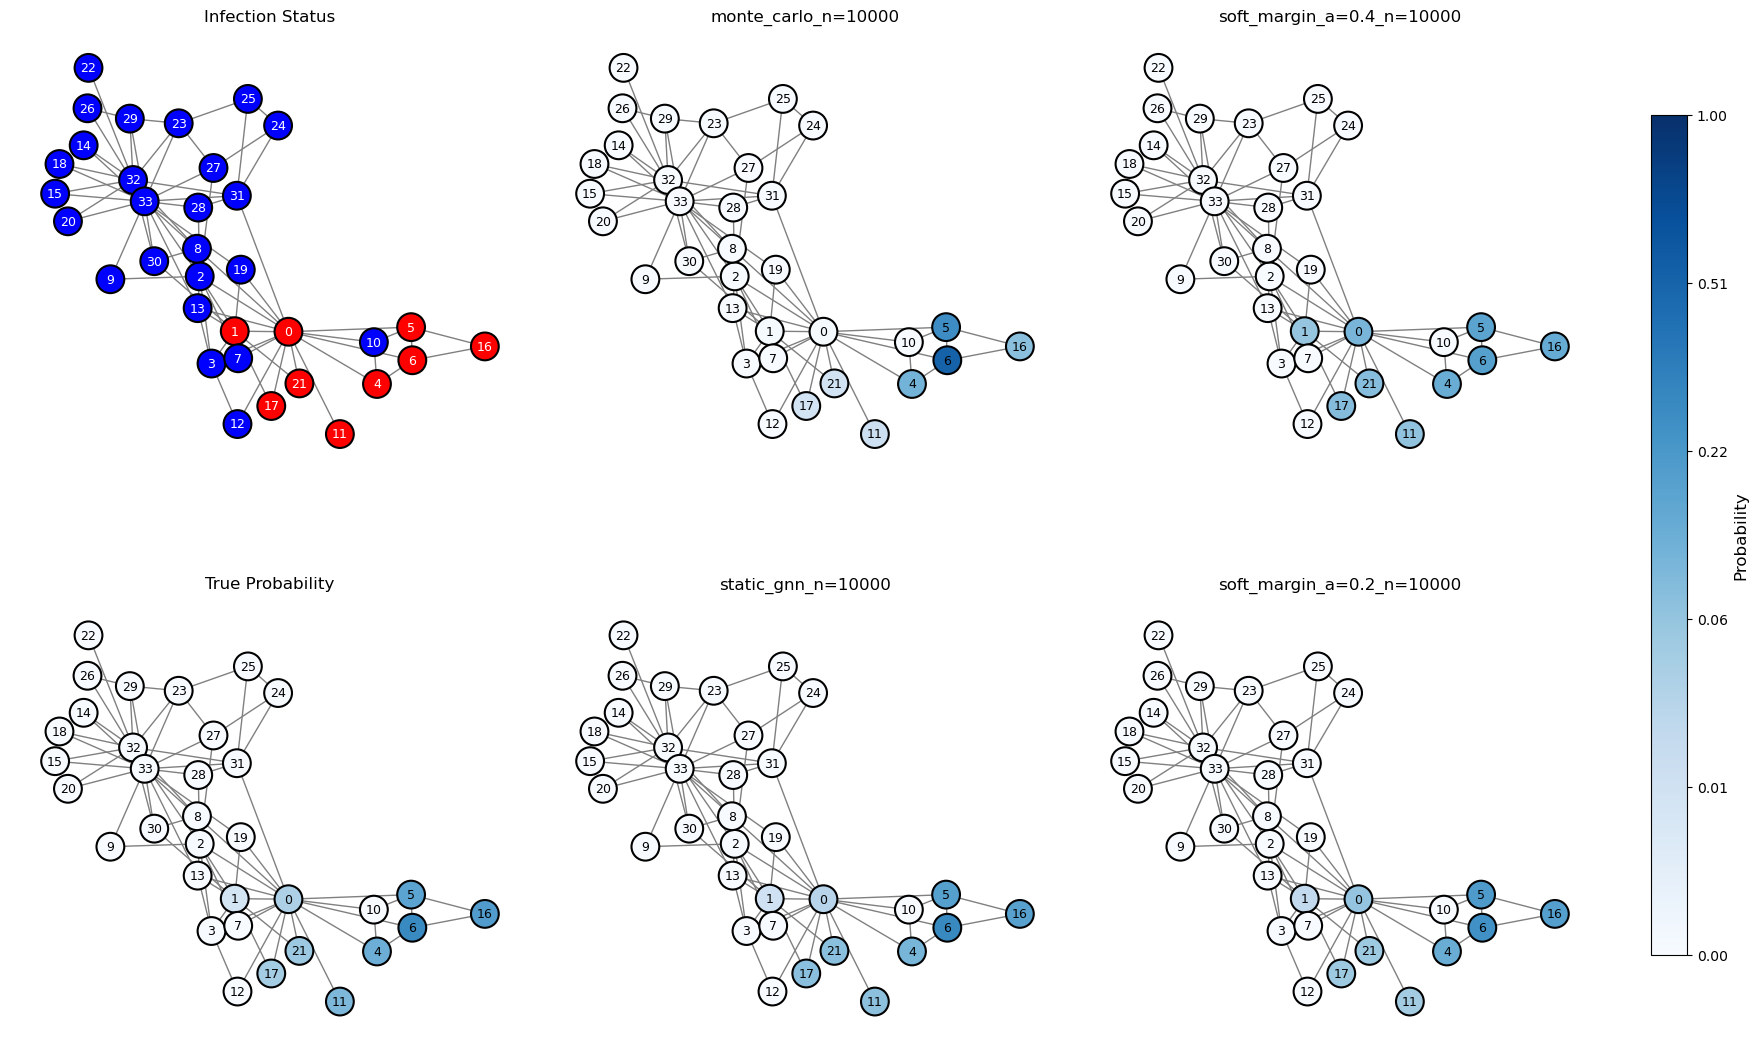

In [172]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

df = dfs[1]
models_to_plot = model_columns[1:]  # The 4 models to plot on the right side

# Transformation parameter: a between 0 and 1
# a=0.5 gives sqrt transformation, a=1 gives linear, a=0 gives log-like (not exactly)
transformation_a = 1/3  # Change this value as needed

# Create position layout (use same for all plots)
pos = nx.spring_layout(G, seed=42)  # seed for reproducibility

# Get node order
node_order = list(G.nodes())

# Create dictionaries for faster lookup
df_indexed = df.set_index('node')
infected_dict = df_indexed['infected'].to_dict()

# Get node colors for infection status
node_colors_infected = ['red' if infected_dict[node] == 1 else 'blue' for node in node_order]

# Define transformation function
def transform_probs(probs, a):
    """Transform probabilities using x^a for a between 0 and 1"""
    return np.power(probs, a)

# Create figure with 2x3 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot 1 (upper left): Infection status with solid borders
ax = axes[0, 0]
nx.draw(G, pos=pos, ax=ax,
        node_color=node_colors_infected,
        with_labels=True,
        node_size=400,
        font_size=9,
        font_color='white',
        edgecolors='black',
        linewidths=1.5,
        edge_color='gray')
ax.set_title("Infection Status", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# Plot 2 (lower left): True probability
ax = axes[1, 0]
true_probs = df_indexed['true_prob'].to_dict()
node_probs_true = [true_probs[node] for node in node_order]
node_probs_transformed_true = transform_probs(np.array(node_probs_true), transformation_a)

nodes_true = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed_true,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)

nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
ax.set_title("True Probability", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_frame_on(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Plot the remaining 4 models
all_transformed_probs = [node_probs_transformed_true]  # Start with true probs for colorbar scaling

for i, model in enumerate(models_to_plot, start=1):
    row = 0 if i <= 2 else 1  # 0 for first two models (top row), 1 for last two (bottom row)
    col = 1 if i % 2 == 1 else 2  # 1 for odd i (left), 2 for even i (right)
    
    ax = axes[row, col]
    
    # Get probabilities for this model
    prob_dict = df_indexed[model].to_dict()
    node_probs = [prob_dict[node] for node in node_order]
    node_probs_transformed = transform_probs(np.array(node_probs), transformation_a)
    all_transformed_probs.append(node_probs_transformed)  # Collect for colorbar scaling
    
    # Draw nodes
    nodes = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)
    
    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
    nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
    ax.set_title(model, fontsize=12)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

# Create one colorbar for all probability plots
# Calculate vmax from transformation of 1
vmax_transformed = transform_probs(np.array([1]), transformation_a)[0]

# Create a single colorbar on the right side
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]

# Create colorbar with transformed scale
norm = plt.Normalize(vmin=0, vmax=vmax_transformed)
sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cbar_ax)

# Set custom tick labels to show original probability values
# We need to show transformed tick positions but label with original values
ticks_transformed = np.linspace(0, vmax_transformed, 6)
# Inverse transform to get original probability values for labels
if transformation_a > 0:
    tick_labels = [f"{(tick ** (1/transformation_a)):.2f}" for tick in ticks_transformed]
else:
    # Handle a=0 case (though it's not really defined)
    tick_labels = [f"{tick:.2f}" for tick in ticks_transformed]
    
cbar.set_ticks(ticks_transformed)
cbar.set_ticklabels(tick_labels)
cbar.set_label('Probability', fontsize=12)
#cbar.ax.text(1.5, 1.02, f'Transformation: x^{transformation_a:.2f}', transform=cbar.ax.transAxes, fontsize=10, va='bottom')

plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar
plt.show()

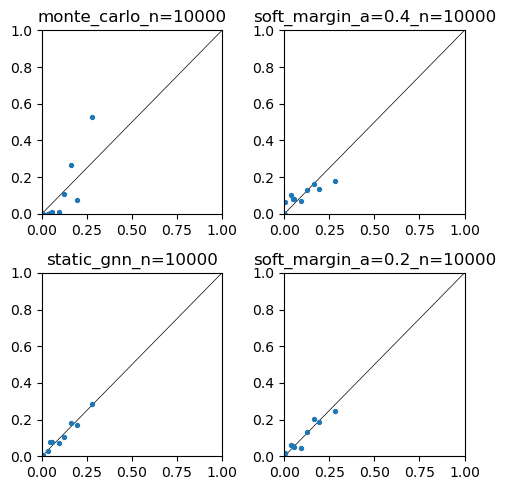

In [173]:
df = dfs[1]

fig, axs = plt.subplots(2, 2, figsize=(5,5))

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    ax.scatter(df["true_prob"], df[model_pred], s=8)
    ax.plot([0,1],[0,1], color="black", lw=0.5, zorder=-10)
    ax.set_title(model_pred)
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

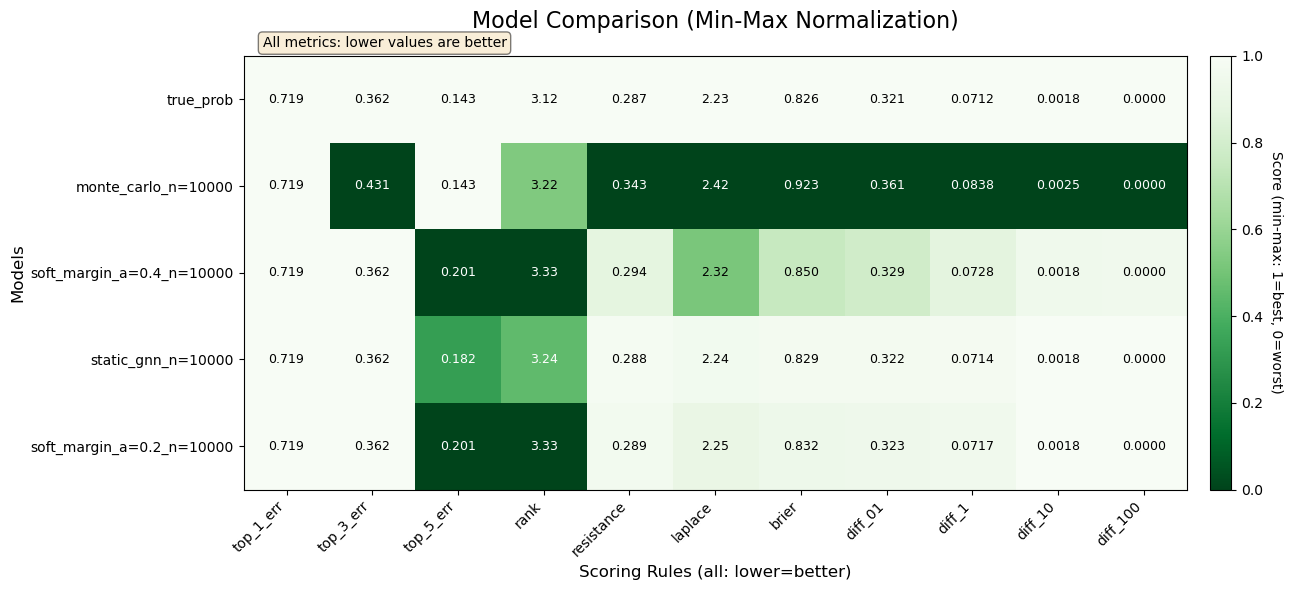

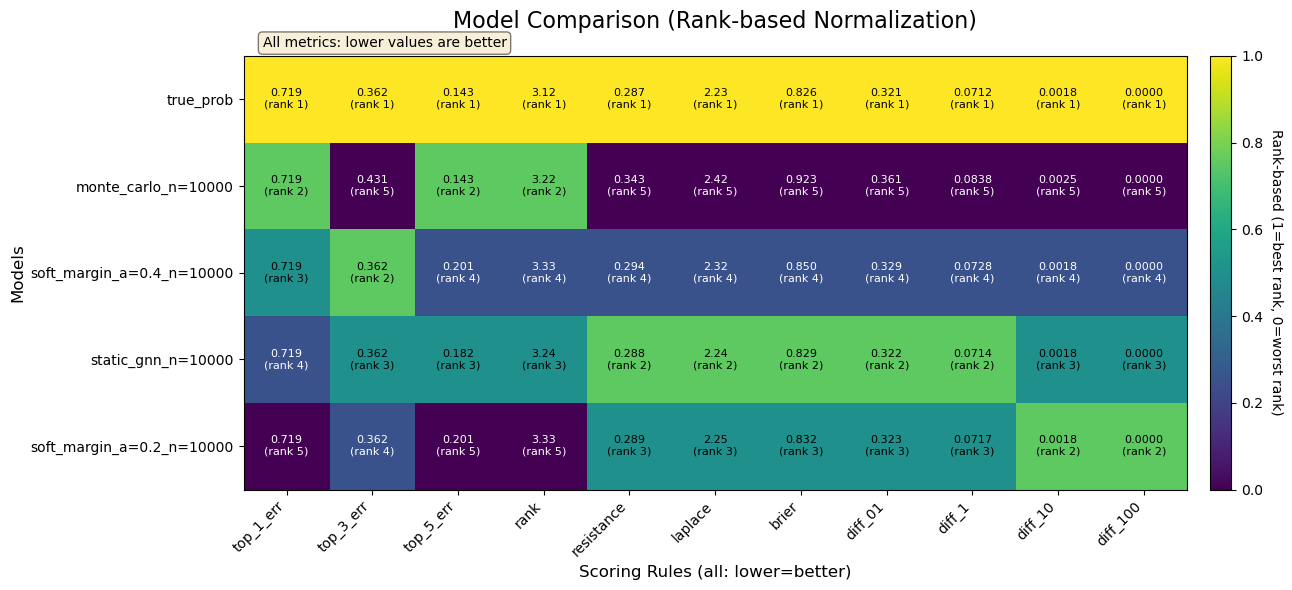

In [174]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[1], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

### Example run 4 for paper

In [178]:
model_columns = ['true_prob', 'monte_carlo_n=1000', 
    'soft_margin_a=0.2_n=1000', 'static_gnn_n=1000', 'soft_margin_a=0.1_n=10000'
]

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_13988\2391459856.py:138: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar


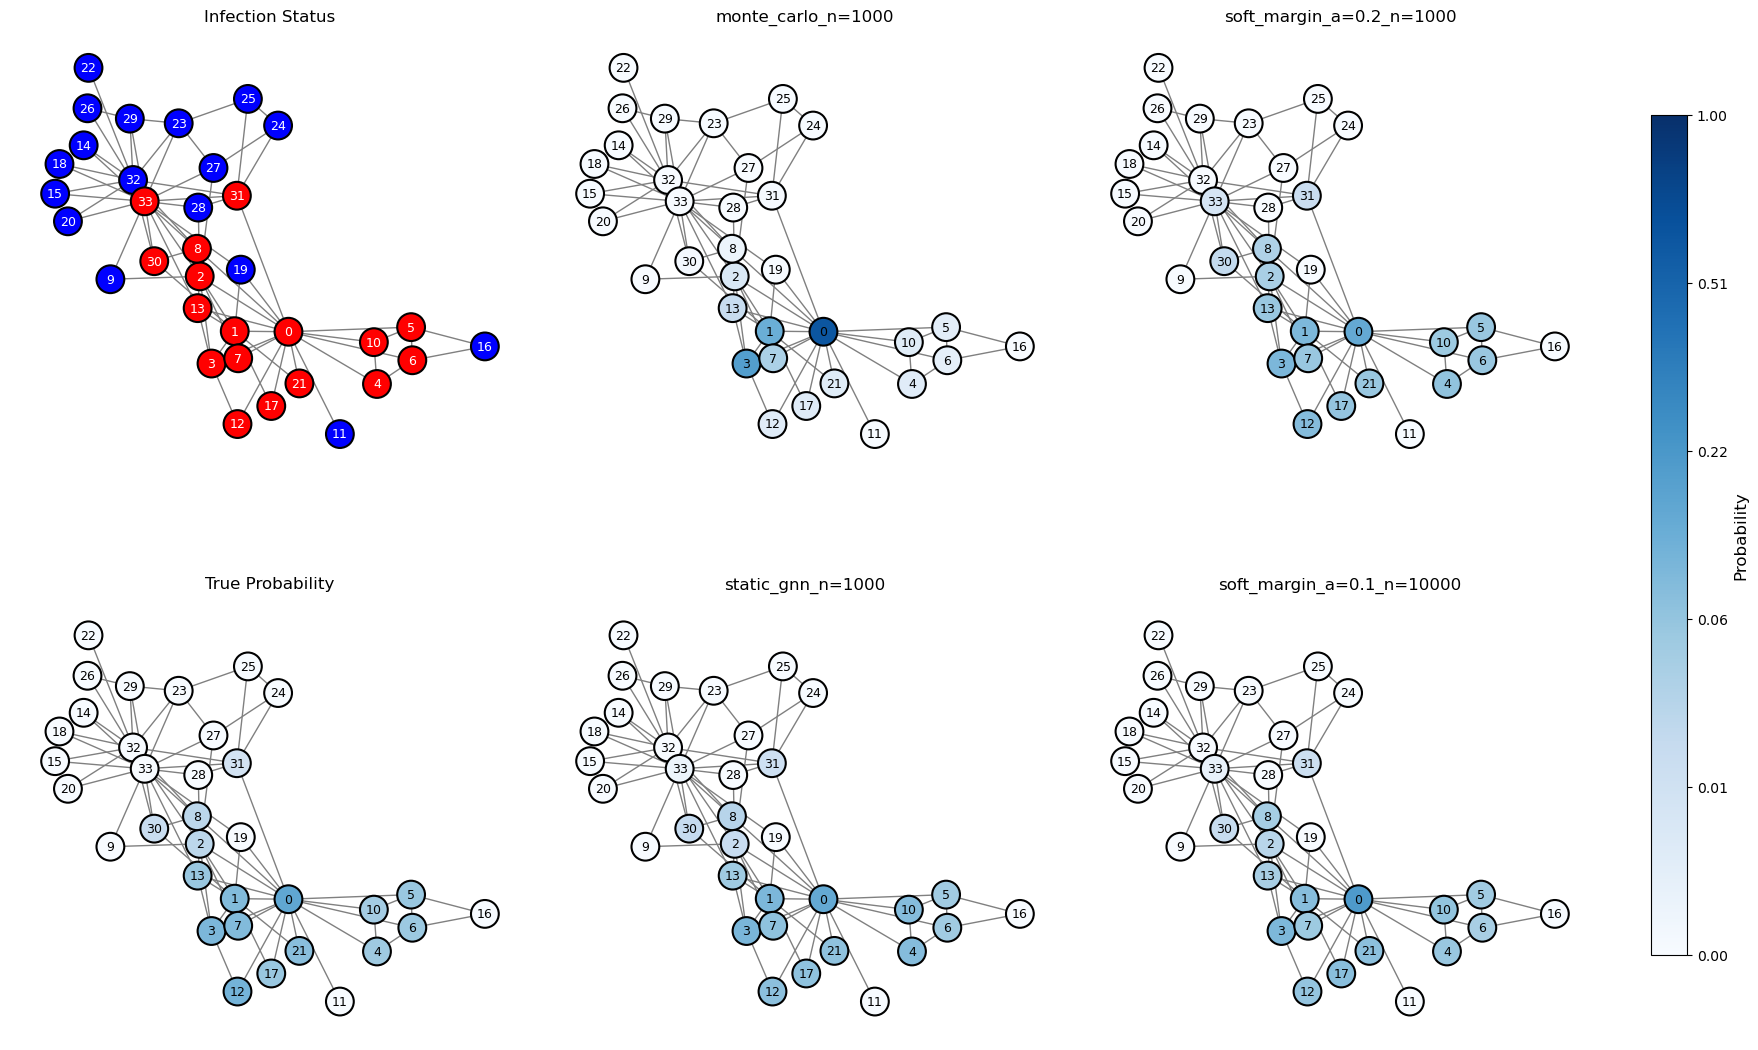

In [179]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

df = dfs[4]
models_to_plot = model_columns[1:]  # The 4 models to plot on the right side

# Transformation parameter: a between 0 and 1
# a=0.5 gives sqrt transformation, a=1 gives linear, a=0 gives log-like (not exactly)
transformation_a = 1/3  # Change this value as needed

# Create position layout (use same for all plots)
pos = nx.spring_layout(G, seed=42)  # seed for reproducibility

# Get node order
node_order = list(G.nodes())

# Create dictionaries for faster lookup
df_indexed = df.set_index('node')
infected_dict = df_indexed['infected'].to_dict()

# Get node colors for infection status
node_colors_infected = ['red' if infected_dict[node] == 1 else 'blue' for node in node_order]

# Define transformation function
def transform_probs(probs, a):
    """Transform probabilities using x^a for a between 0 and 1"""
    return np.power(probs, a)

# Create figure with 2x3 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot 1 (upper left): Infection status with solid borders
ax = axes[0, 0]
nx.draw(G, pos=pos, ax=ax,
        node_color=node_colors_infected,
        with_labels=True,
        node_size=400,
        font_size=9,
        font_color='white',
        edgecolors='black',
        linewidths=1.5,
        edge_color='gray')
ax.set_title("Infection Status", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# Plot 2 (lower left): True probability
ax = axes[1, 0]
true_probs = df_indexed['true_prob'].to_dict()
node_probs_true = [true_probs[node] for node in node_order]
node_probs_transformed_true = transform_probs(np.array(node_probs_true), transformation_a)

nodes_true = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed_true,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)

nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
ax.set_title("True Probability", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_frame_on(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Plot the remaining 4 models
all_transformed_probs = [node_probs_transformed_true]  # Start with true probs for colorbar scaling

for i, model in enumerate(models_to_plot, start=1):
    row = 0 if i <= 2 else 1  # 0 for first two models (top row), 1 for last two (bottom row)
    col = 1 if i % 2 == 1 else 2  # 1 for odd i (left), 2 for even i (right)
    
    ax = axes[row, col]
    
    # Get probabilities for this model
    prob_dict = df_indexed[model].to_dict()
    node_probs = [prob_dict[node] for node in node_order]
    node_probs_transformed = transform_probs(np.array(node_probs), transformation_a)
    all_transformed_probs.append(node_probs_transformed)  # Collect for colorbar scaling
    
    # Draw nodes
    nodes = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed,
                                   cmap=plt.cm.Blues,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)
    
    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
    nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
    ax.set_title(model, fontsize=12)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

# Create one colorbar for all probability plots
# Calculate vmax from transformation of 1
vmax_transformed = transform_probs(np.array([1]), transformation_a)[0]

# Create a single colorbar on the right side
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]

# Create colorbar with transformed scale
norm = plt.Normalize(vmin=0, vmax=vmax_transformed)
sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cbar_ax)

# Set custom tick labels to show original probability values
# We need to show transformed tick positions but label with original values
ticks_transformed = np.linspace(0, vmax_transformed, 6)
# Inverse transform to get original probability values for labels
if transformation_a > 0:
    tick_labels = [f"{(tick ** (1/transformation_a)):.2f}" for tick in ticks_transformed]
else:
    # Handle a=0 case (though it's not really defined)
    tick_labels = [f"{tick:.2f}" for tick in ticks_transformed]
    
cbar.set_ticks(ticks_transformed)
cbar.set_ticklabels(tick_labels)
cbar.set_label('Probability', fontsize=12)
#cbar.ax.text(1.5, 1.02, f'Transformation: x^{transformation_a:.2f}', transform=cbar.ax.transAxes, fontsize=10, va='bottom')

plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar
plt.show()

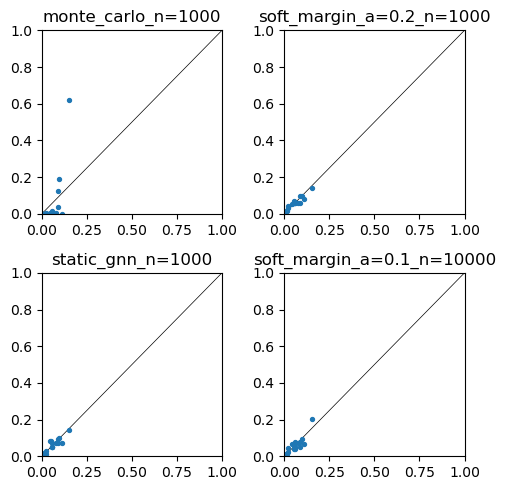

In [180]:
df = dfs[4]

fig, axs = plt.subplots(2, 2, figsize=(5,5))

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    ax.scatter(df["true_prob"], df[model_pred], s=8)
    ax.plot([0,1],[0,1], color="black", lw=0.5, zorder=-10)
    ax.set_title(model_pred)
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

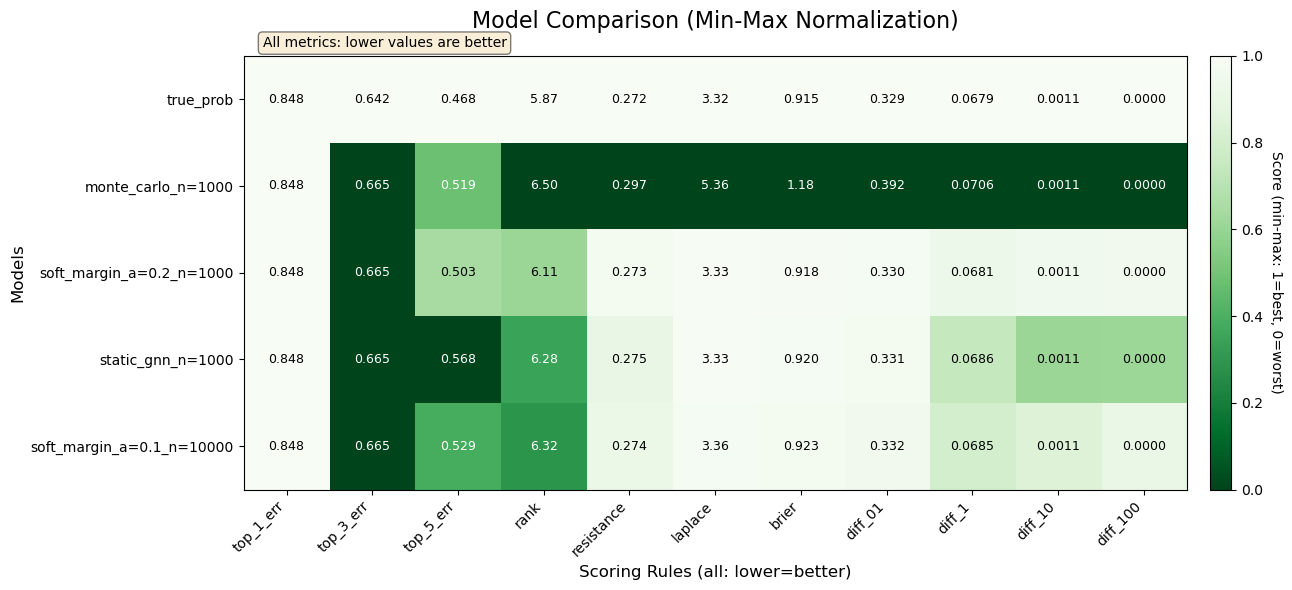

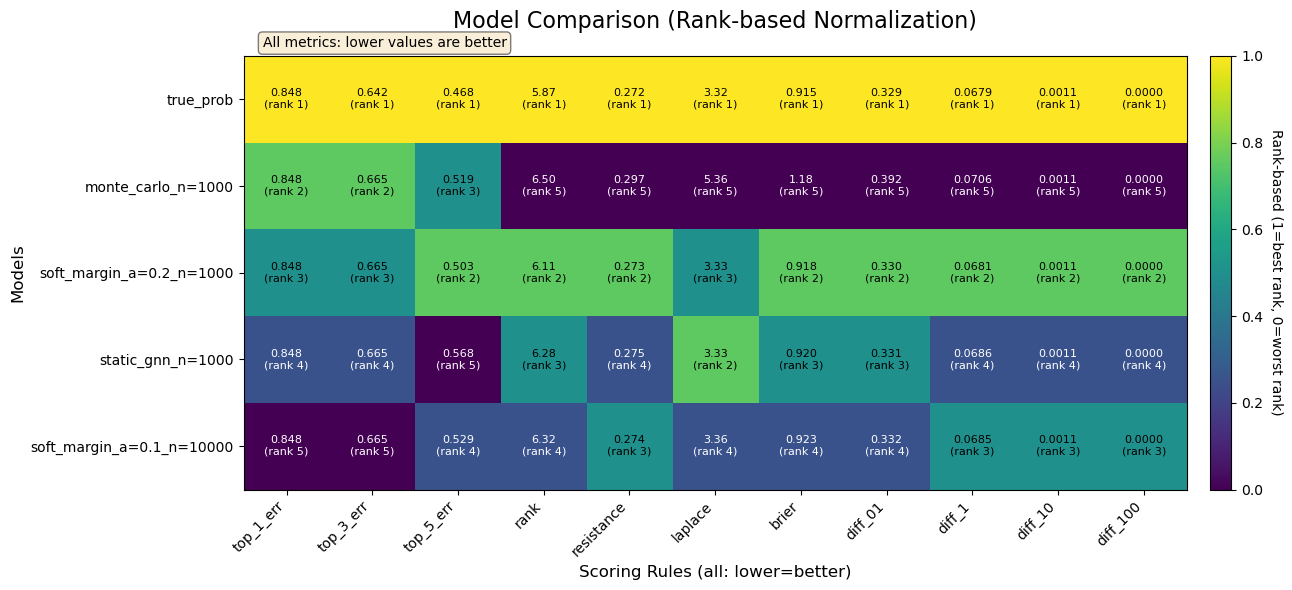

In [182]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[4], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

### Example run 1b for paper

In [376]:

# slightly modified model that has more probability mass on the left cluster
dfs[1]["soft_margin_a=0.1_n=1000_modified"] = dfs[1]["soft_margin_a=0.1_n=1000"]
dfs[1].loc[6,"soft_margin_a=0.1_n=1000_modified"] = dfs[1].loc[6,"soft_margin_a=0.1_n=1000_modified"] - 0.01
dfs[1].loc[16,"soft_margin_a=0.1_n=1000_modified"] = dfs[1].loc[16,"soft_margin_a=0.1_n=1000_modified"] - 0.01
dfs[1].loc[11,"soft_margin_a=0.1_n=1000_modified"] = dfs[1].loc[11,"soft_margin_a=0.1_n=1000_modified"] + 0.02

# two point masses (with mass of cluster)
true_prob_cluster_4_5_6_16 = dfs[1][dfs[1]["node"].isin([4,5,6,16])].sum()["true_prob"]
true_prob_cluster_1_11_17_21 = dfs[1][dfs[1]["node"].isin([1,11,17,21])].sum()["true_prob"]
prob_0 = dfs[1][dfs[1]["node"]==0].sum()["true_prob"]
dfs[1]["two_point_masses"] = 0
dfs[1].loc[6,"two_point_masses"] = true_prob_cluster_4_5_6_16
dfs[1].loc[11,"two_point_masses"] = true_prob_cluster_1_11_17_21 + prob_0

# piecewise uniform distribution with correct probability mass on two main clusters
dfs[1]["piecewise_uniform"] = dfs[1]["true_prob"]
dfs[1].loc[4,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[5,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[6,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[16,"piecewise_uniform"] = true_prob_cluster_4_5_6_16/4
dfs[1].loc[1,"piecewise_uniform"] = true_prob_cluster_1_11_17_21/4
dfs[1].loc[11,"piecewise_uniform"] = true_prob_cluster_1_11_17_21/4
dfs[1].loc[17,"piecewise_uniform"] = true_prob_cluster_1_11_17_21/4
dfs[1].loc[21,"piecewise_uniform"] = true_prob_cluster_1_11_17_21/4

display(dfs[1]["two_point_masses"].sum(), dfs[1]["piecewise_uniform"].sum())

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_13988\2510884004.py:12: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.7629107981220656' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  dfs[1].loc[6,"two_point_masses"] = true_prob_cluster_4_5_6_16


np.float64(0.9999999999999996)

np.float64(0.9999999999999994)

In [389]:
model_columns = ['true_prob', 'static_gnn_n=10000', 'monte_carlo_n=1000', 
    'soft_margin_a=0.2_n=10000', 'soft_margin_a=0.1_n=1000' #, 'static_gnn_n=10000', 'soft_margin_a=0.4_n=10000'
]

C:\Users\ma1201204\AppData\Local\Temp\ipykernel_13988\1913645822.py:141: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar


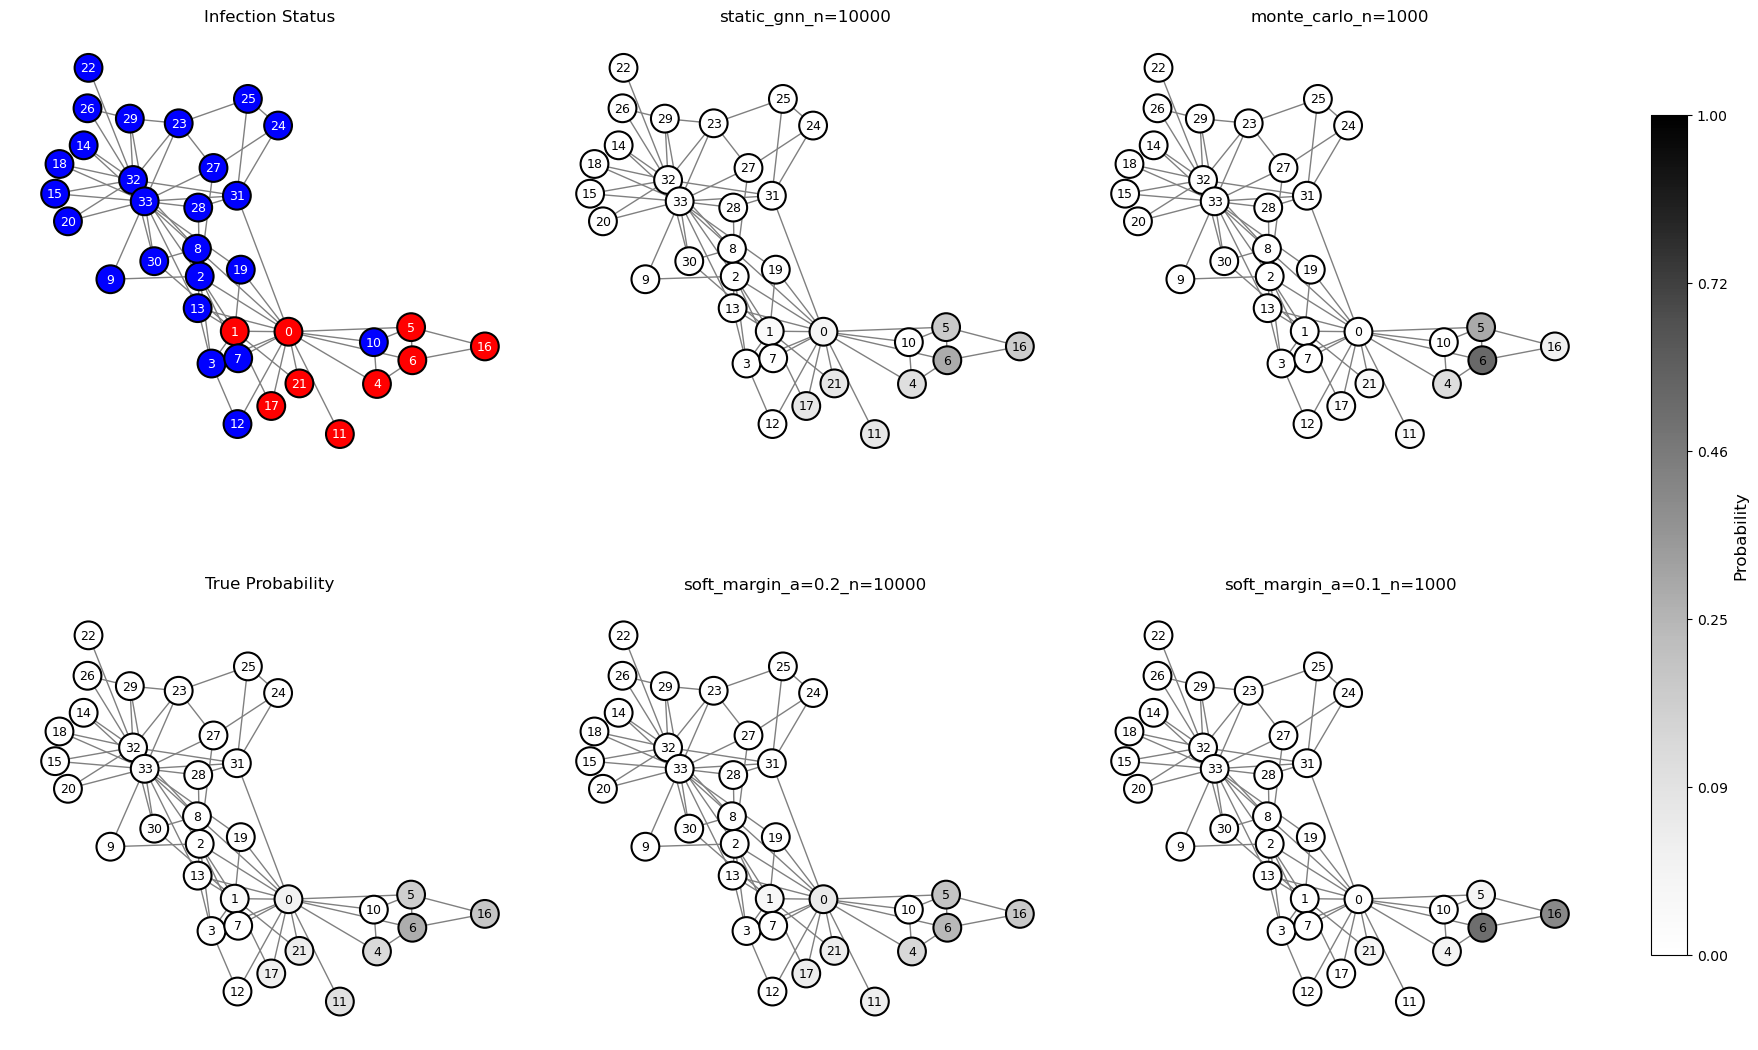

In [390]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

df = dfs[1]
models_to_plot = model_columns[1:]  # The 4 models to plot on the right side

# Transformation parameter: a between 0 and 1
# a=0.5 gives sqrt transformation, a=1 gives linear, a=0 gives log-like (not exactly)
transformation_a = 1/1.5  # Change this value as needed

# colormap
cmap = plt.cm.Grays

# Create position layout (use same for all plots)
pos = nx.spring_layout(G, seed=42)  # seed for reproducibility

# Get node order
node_order = list(G.nodes())

# Create dictionaries for faster lookup
df_indexed = df.set_index('node')
infected_dict = df_indexed['infected'].to_dict()

# Get node colors for infection status
node_colors_infected = ['red' if infected_dict[node] == 1 else 'blue' for node in node_order]

# Define transformation function
def transform_probs(probs, a):
    """Transform probabilities using x^a for a between 0 and 1"""
    return np.power(probs, a)

# Create figure with 2x3 subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Flatten axes for easier indexing
axes_flat = axes.flatten()

# Plot 1 (upper left): Infection status with solid borders
ax = axes[0, 0]
nx.draw(G, pos=pos, ax=ax,
        node_color=node_colors_infected,
        with_labels=True,
        node_size=400,
        font_size=9,
        font_color='white',
        edgecolors='black',
        linewidths=1.5,
        edge_color='gray')
ax.set_title("Infection Status", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# Plot 2 (lower left): True probability
ax = axes[1, 0]
true_probs = df_indexed['true_prob'].to_dict()
node_probs_true = [true_probs[node] for node in node_order]
node_probs_transformed_true = transform_probs(np.array(node_probs_true), transformation_a)

nodes_true = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed_true,
                                   cmap=cmap,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)

nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
ax.set_title("True Probability", fontsize=12)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
ax.set_frame_on(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Plot the remaining 4 models
all_transformed_probs = [node_probs_transformed_true]  # Start with true probs for colorbar scaling

for i, model in enumerate(models_to_plot, start=1):
    row = 0 if i <= 2 else 1  # 0 for first two models (top row), 1 for last two (bottom row)
    col = 1 if i % 2 == 1 else 2  # 1 for odd i (left), 2 for even i (right)
    
    ax = axes[row, col]
    
    # Get probabilities for this model
    prob_dict = df_indexed[model].to_dict()
    node_probs = [prob_dict[node] for node in node_order]
    node_probs_transformed = transform_probs(np.array(node_probs), transformation_a)
    all_transformed_probs.append(node_probs_transformed)  # Collect for colorbar scaling
    
    # Draw nodes
    nodes = nx.draw_networkx_nodes(G, pos=pos, ax=ax,
                                   node_color=node_probs_transformed,
                                   cmap=cmap,
                                   node_size=400,
                                   vmin=0, vmax=transform_probs(np.array([1]), transformation_a)[0],
                                   edgecolors='black',
                                   linewidths=1.5)
    
    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color='gray')
    nx.draw_networkx_labels(G, pos=pos, ax=ax, font_size=9)
    ax.set_title(model, fontsize=12)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

# Create one colorbar for all probability plots
# Calculate vmax from transformation of 1
vmax_transformed = transform_probs(np.array([1]), transformation_a)[0]

# Create a single colorbar on the right side
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]

# Create colorbar with transformed scale
norm = plt.Normalize(vmin=0, vmax=vmax_transformed)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cbar_ax)

# Set custom tick labels to show original probability values
# We need to show transformed tick positions but label with original values
ticks_transformed = np.linspace(0, vmax_transformed, 6)
# Inverse transform to get original probability values for labels
if transformation_a > 0:
    tick_labels = [f"{(tick ** (1/transformation_a)):.2f}" for tick in ticks_transformed]
else:
    # Handle a=0 case (though it's not really defined)
    tick_labels = [f"{tick:.2f}" for tick in ticks_transformed]
    
cbar.set_ticks(ticks_transformed)
cbar.set_ticklabels(tick_labels)
cbar.set_label('Probability', fontsize=12)
#cbar.ax.text(1.5, 1.02, f'Transformation: x^{transformation_a:.2f}', transform=cbar.ax.transAxes, fontsize=10, va='bottom')

plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar
plt.show()

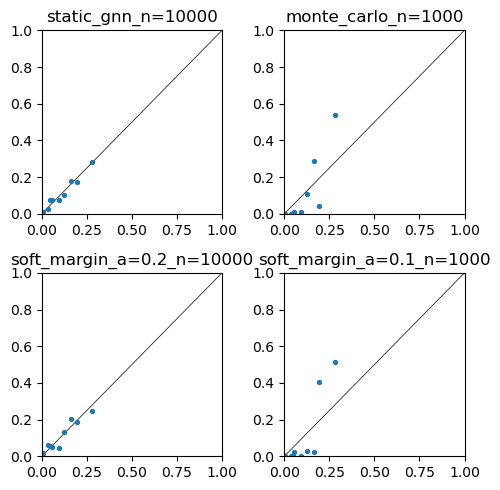

In [391]:
df = dfs[1]

fig, axs = plt.subplots(2, 2, figsize=(5,5))

for ax, model_pred in zip(axs.flatten(), model_columns[1:]):
    ax.scatter(df["true_prob"], df[model_pred], s=8)
    ax.plot([0,1],[0,1], color="black", lw=0.5, zorder=-10)
    ax.set_title(model_pred)
    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

plt.tight_layout()
plt.show()

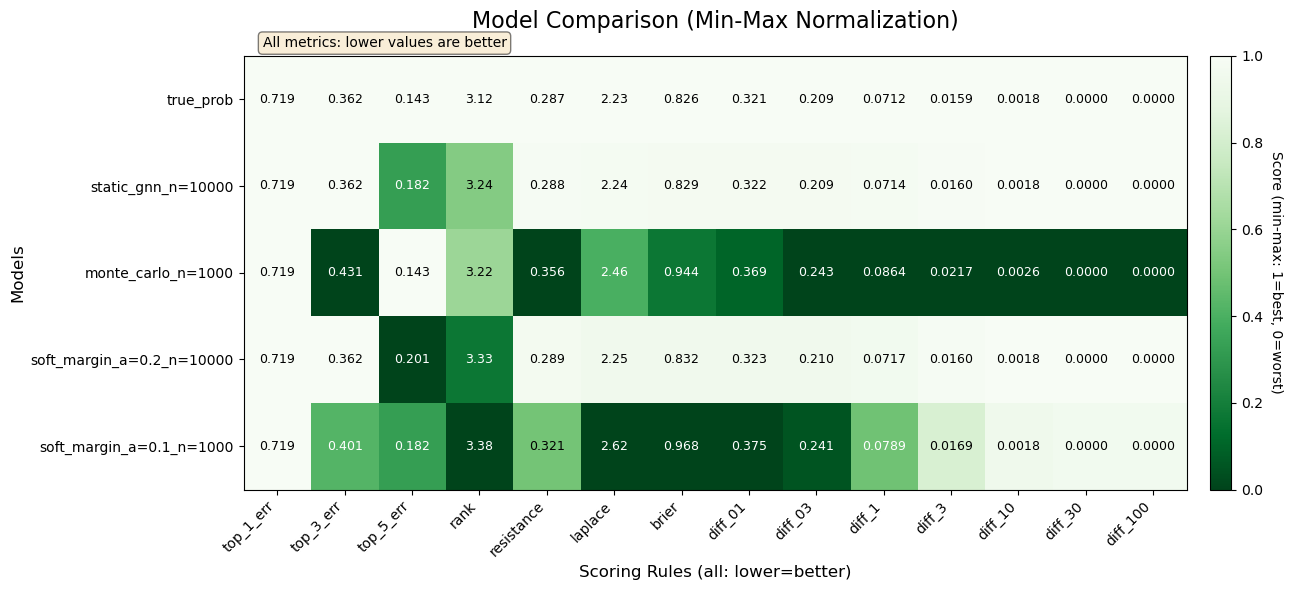

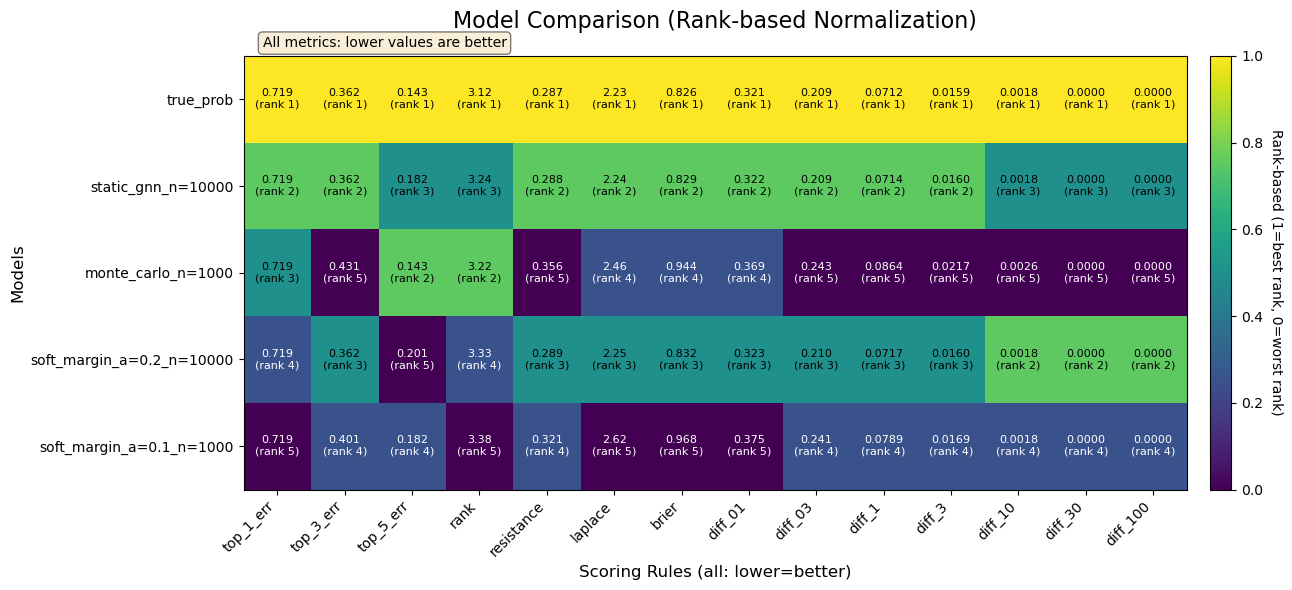

In [392]:
# Suppress only PerformanceWarning
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

res_df = compute_scores_efficiently(adjacency_matrix, dfs[1], model_columns=model_columns, scoring_rules=scoring_rules)
Escores_df = compute_expected_scores(res_df, model_columns, scoring_rule_names=scoring_rules.keys())
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='minmax')
plt.show()
fig, ax, matrix_norm = plot_expected_scores_heatmap(Escores_df, normalize_by='rank')
plt.show()

# Re-enable warnings after this cell (optional)
warnings.filterwarnings('default', category=pd.errors.PerformanceWarning)

In [393]:
df_support = dfs[1][dfs[1]["infected"]==1][["node"]+model_columns]
df_support

,node,true_prob,static_gnn_n=10000,monte_carlo_n=1000,soft_margin_a=0.2_n=10000,soft_margin_a=0.1_n=1000
0,0,0.036385,0.026700,8.067218e-07,0.063796,0.000830
1,1,0.005869,0.008441,6.068619e-07,0.018213,0.000004
4,4,0.124413,0.104186,1.076719e-01,0.130838,0.028335
5,5,0.164319,0.179218,2.883707e-01,0.205097,0.024625
6,6,0.280516,0.283074,5.385857e-01,0.244615,0.513181
11,11,0.093897,0.074876,9.831190e-03,0.046792,0.000278
16,16,0.193662,0.172351,4.204385e-02,0.184146,0.407594
17,17,0.045775,0.075577,5.096641e-03,0.053334,0.000153
21,21,0.055164,0.075577,8.398611e-03,0.053168,0.025001


In [394]:
df_support[df_support["node"].isin([4,5,6,16])].sum()

node                         31.000000
true_prob                     0.762911
static_gnn_n=10000            0.738828
monte_carlo_n=1000            0.976672
soft_margin_a=0.2_n=10000     0.764696
soft_margin_a=0.1_n=1000      0.973735
dtype: float64